# BeeMonitor 2024 field study: paper figures

This notebook holds all the code behind the seven main figures of the paper. It needs only the CSV files in `data/`. Run it top to bottom (**Run All**, about 30 s); each figure is shown and also saved as PNG and PDF in `output/`.

| Section | Figure |
|---|---|
| 2 | Recorded video by site, day and time of day |
| 3 | Computer-vision evaluation: precision and recall of events and trips |
| 4 | Foraging trips and provisioned cells per nest tube (Site 1, Site 2) |
| 5 | Daily foraging trips and land cover |
| 6 | Foraging trips vs provisioned cells |
| 7 | Median trip duration per tube between sites |

## 1. Setup, data and definitions

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from scipy.stats import linregress, mannwhitneyu, t as t_dist
from scipy.stats import binomtest

DATA, OUT = Path("data"), Path("output")
OUT.mkdir(exist_ok=True)

# colours: Paul Tol "muted" palette (colour-blind safe); one colour per site in every figure
INK, MUTED, LIGHT = "#0b0b0b", "#52514e", "#ebeae6"
SITE_LABELS = {"mendels": "Site 1", "natalies": "Site 2"}
SITE_COLORS = {"mendels": "#332288", "natalies": "#44AA99"}
ROUND_STYLE = {1: dict(marker="o", filled=True, ls="-"), 2: dict(marker="^", filled=False, ls="--")}
LANDCOVER_COLORS = {"Forest": "#117733", "Pasture/hay": "#DDCC77", "Corn": "#CC6677", "Soybean": "#882255",
                    "Developed": "#8a8984", "Other": "#d9d8d3"}


def apply_style() -> None:
    """Shared type scale and axis styling."""
    plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
                         "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 12,
                         "axes.titlelocation": "left", "axes.titlecolor": INK,
                         "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                         "axes.spines.top": False, "axes.spines.right": False})


def save(fig, name: str, width: int = 900, **kw) -> None:
    """Save as PNG and PDF in output/, then show the saved PNG."""
    fig.savefig(OUT / f"{name}.png", dpi=300, **kw)
    fig.savefig(OUT / f"{name}.pdf", **kw)
    plt.close(fig)
    display(Image(filename=str(OUT / f"{name}.png"), width=width))
    mpl.rc_file_defaults()  # each figure starts from the same style

**Definitions used throughout**

- **Sites:** `mendels` = Site 1, `natalies` = Site 2.
- **Nest tubes:** the hotel has a top and a bottom frame, each with three blocks (I–III) of 10 columns (A–J). A nest code such as `MT II-A-3` means Mendels, top frame, block II, column A, cell 3, which is tube 11. Tubes are numbered 1–30 (top) and 31–60 (bottom).
- **Rounds:** nest boards were swapped on 16 May during a recording gap (Site 1: no video 10:50–17:11; Site 2: video only from 18:31). Trips leaving before 14:00 on 16 May belong to Round 1, later trips to Round 2.
- **Trip window:** ecological analyses use trips that start and end between 08:00 and 20:00 on the same day. This drops 4 dusk detections (29 Apr, Site 2).
- **Provisioned cell:** a cell containing pollen and/or larvae. Cells with larvae (alive or dead) are counted separately.
- **Tube-round:** one nest tube in one round, the unit for the regression and the trip-duration test.

In [3]:
DAY_HOURS = (8, 20)
SWAP_DATE = pd.Timestamp("2024-05-16")
SWAP_TIME = pd.Timestamp("2024-05-16 14:00")
PROVISIONED = "Pollen|Larvae"
LARVAE = "Larvae"

ROMAN = {"I": 1, "II": 2, "III": 3}
FRAME_OFFSET = {"T": 0, "B": 30}
SITE_KEY = {"Mendels": "mendels", "Natalie": "natalies"}


def tube_number(frame_id: pd.Series, nest_code: pd.Series) -> pd.Series:
    """MT II-A-3 -> top frame, block II, column A -> tube 11."""
    parts = nest_code.str.split("-", expand=True)
    block = parts[0].map(ROMAN)
    column = parts[1].str.upper().map(lambda c: ord(c) - ord("A") + 1)
    return frame_id.str[1].map(FRAME_OFFSET) + (block - 1) * 10 + column


def in_day_window(trips: pd.DataFrame, hours=DAY_HOURS) -> pd.Series:
    """True for trips that leave and return within the daytime window on the same day."""
    return ((trips["exit_time"].dt.hour >= hours[0]) & (trips["entry_time"].dt.hour < hours[1])
            & (trips["exit_time"].dt.date == trips["entry_time"].dt.date))


files = pd.read_csv(DATA / "files.csv")

nests = pd.read_csv(DATA / "nesting.csv")
nests["tube"] = tube_number(nests["frame_id"], nests["nest_code"])  # nest_code is the reliable tube position
nests["site_name"] = nests["site"].map(SITE_KEY)

trips_raw = pd.read_csv(DATA / "trips.csv", parse_dates=["exit_time", "entry_time"])
trips = trips_raw[in_day_window(trips_raw)].copy()
trips["tube"] = trips["reference"].str.split("_").str[1].astype(int)
trips["release"] = np.where(trips["exit_time"] < SWAP_TIME, 1, 2)

print(f"{len(files):,} recorded clips | {len(trips_raw):,} detected trips, {len(trips):,} within 08:00-20:00 "
      f"| {len(nests)} nest cells")
trips.groupby(["site_name", "release"]).size().rename("trips").unstack().rename(index=SITE_LABELS)

6,305 recorded clips | 21,378 detected trips, 21,374 within 08:00-20:00 | 315 nest cells


release,1,2
site_name,,
Site 1,4922,10527
Site 2,3451,2474


## 2. Recorded video

Each completed 10-min clip is drawn on a day × time-of-day grid. Site 2's early-season block between 20:00 and 06:00 is night video from a scheduler fault (24–28 Apr), fixed on 1 May.

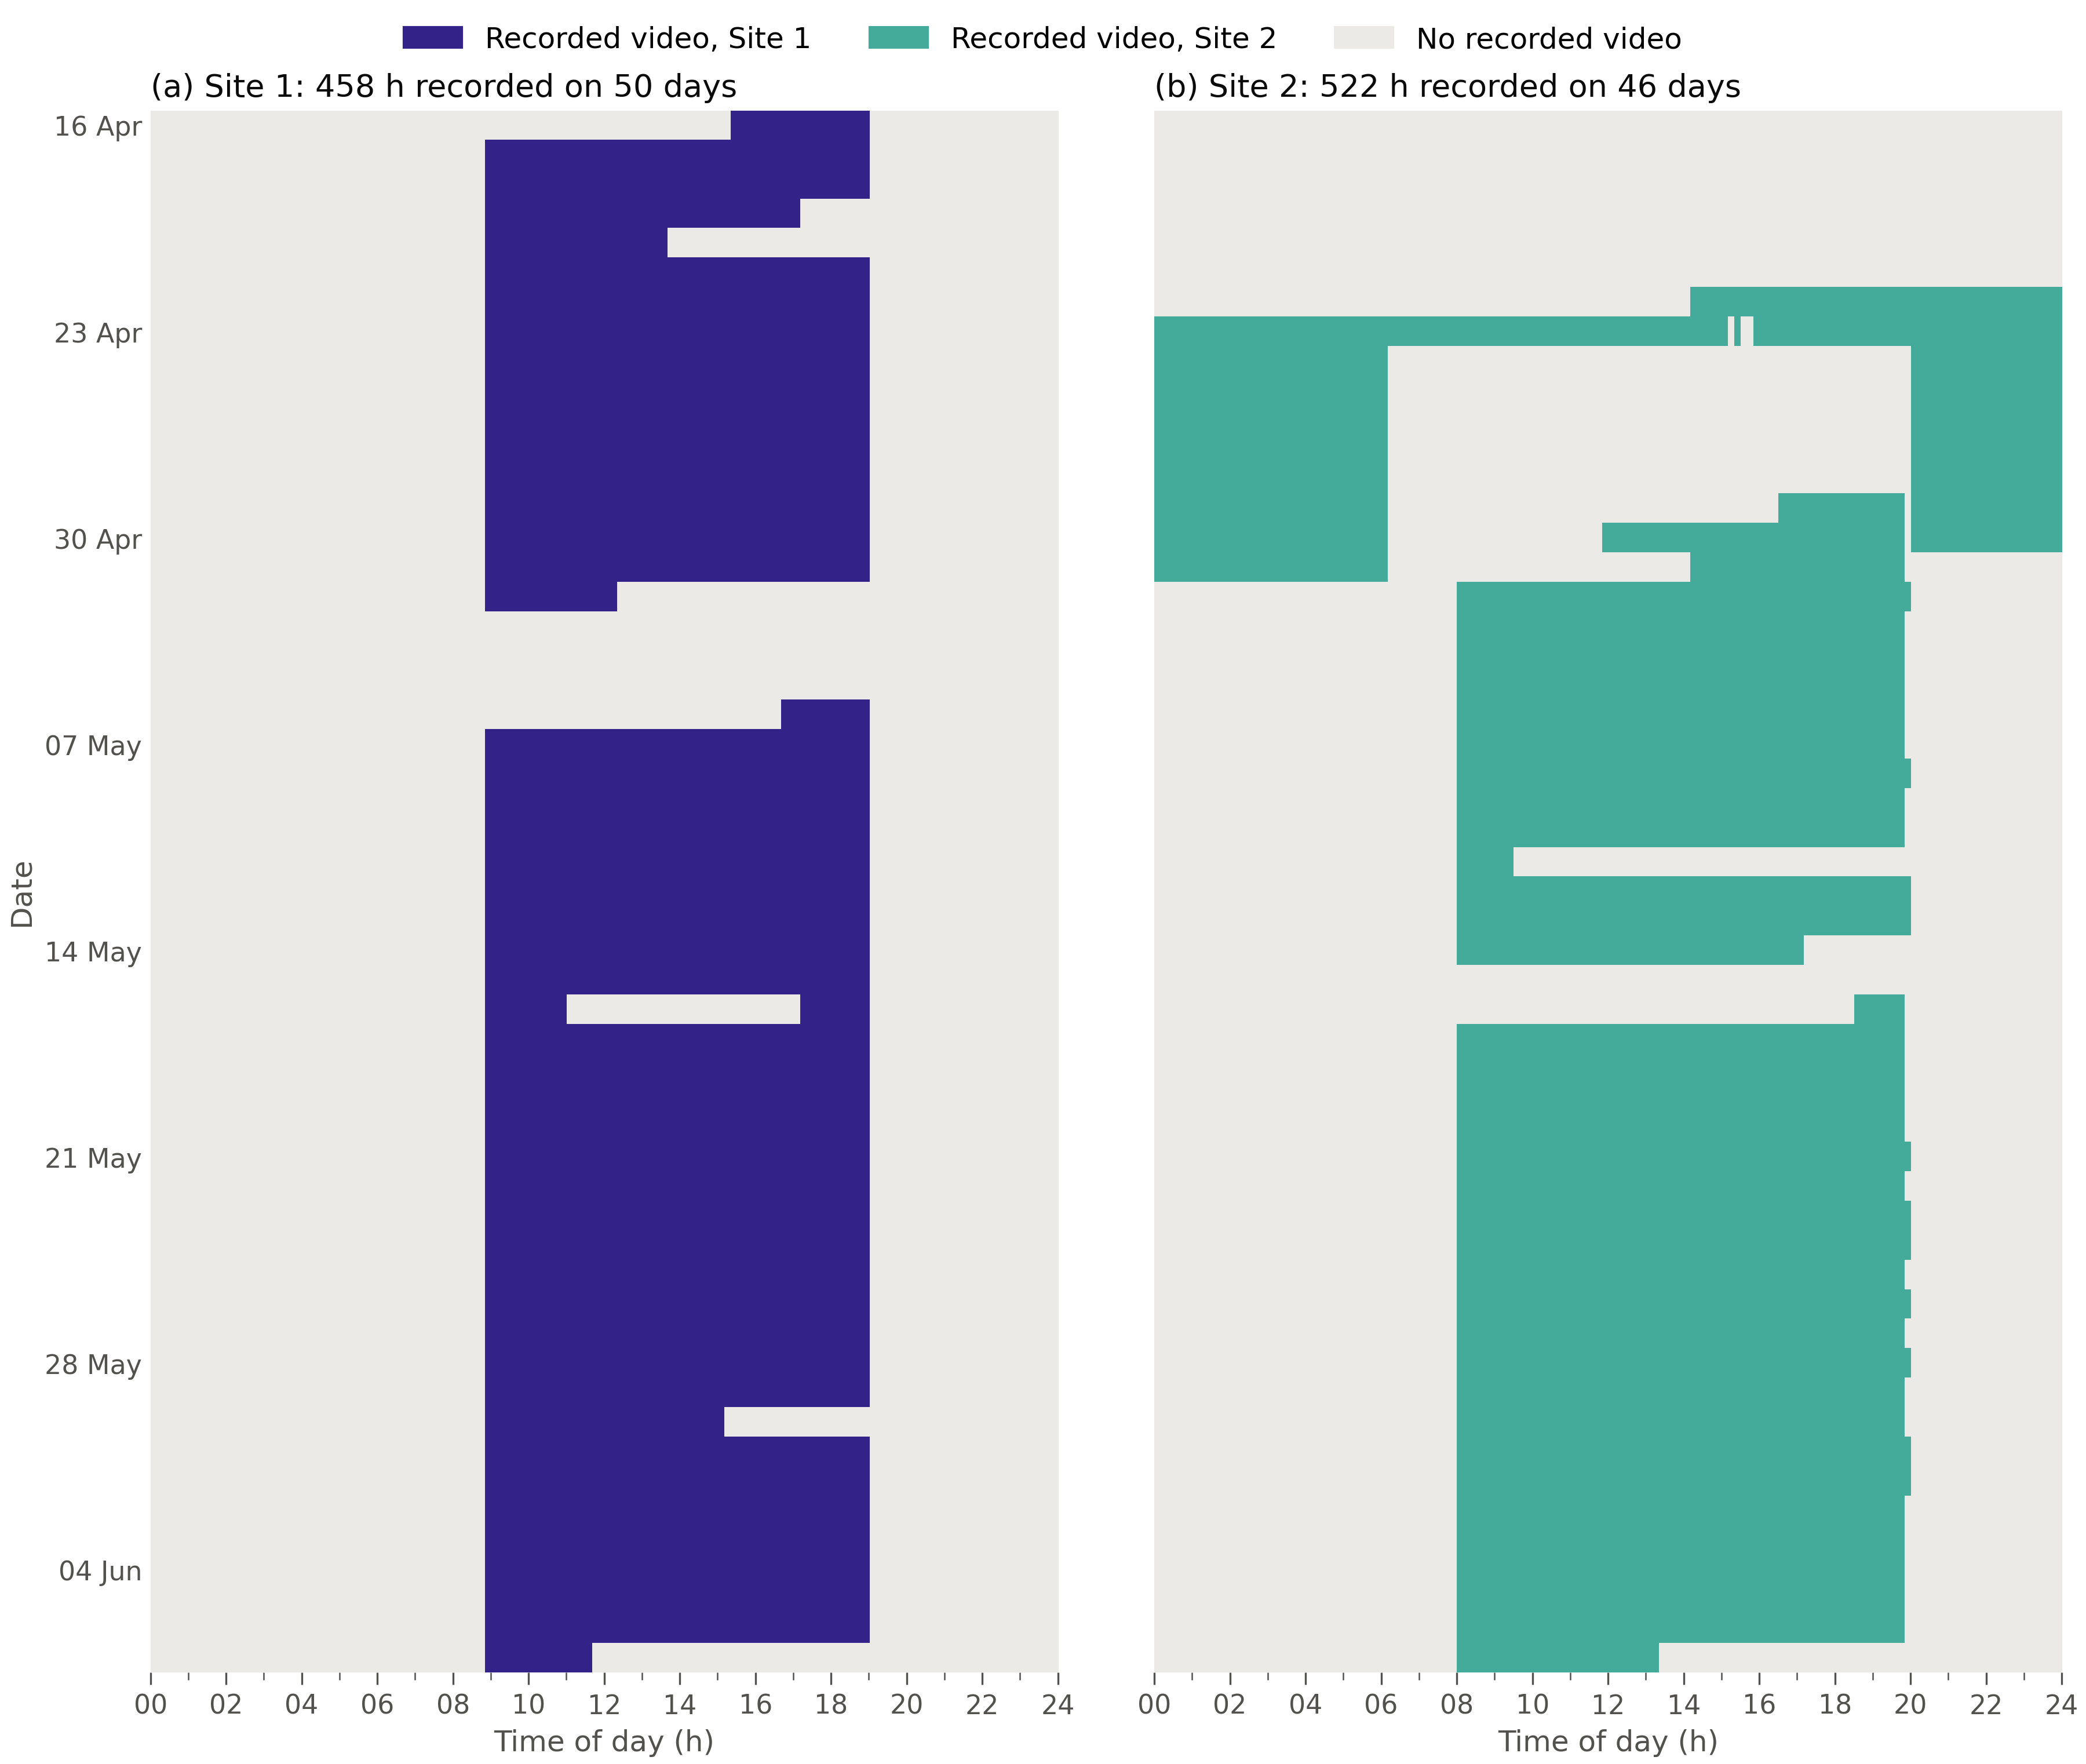

,hours,days,clips
site_name,,,
Site 1,458,50,2777
Site 2,522,46,3153


In [4]:
SLOT_MIN = 10
N_SLOTS = 24 * 60 // SLOT_MIN


def observed_grid(f: pd.DataFrame, dates: pd.DatetimeIndex) -> np.ndarray:
    """True for every 10-min slot covered by a successfully processed clip."""
    ok = f[f["run_status"].eq("completed")]
    start = pd.to_datetime(ok["date"] + " " + ok["start_time"])
    end = start + pd.to_timedelta(ok["duration_min"].fillna(10), unit="min")  # missing length: a full clip
    grid = np.zeros((len(dates), N_SLOTS), dtype=bool)
    for s, e in zip(start, end):
        row = (s.normalize() - dates[0]).days
        a = (s.hour * 60 + s.minute) // SLOT_MIN
        b = max(a + 1, int(np.ceil((e.hour * 60 + e.minute + e.second / 60) / SLOT_MIN)))
        grid[row, a:min(b, N_SLOTS)] = True
    return grid


apply_style()
dates = pd.date_range(files["date"].min(), files["date"].max(), freq="D")
fig, axes = plt.subplots(1, 2, figsize=(12, 0.15 * len(dates) + 2.2), sharey=True, constrained_layout=True)
fig.get_layout_engine().set(wspace=0.06)
for i, (ax, site) in enumerate(zip(axes, sorted(SITE_LABELS))):
    s = files[files["site_name"] == site]
    grid = observed_grid(s, dates)
    ax.imshow(grid, cmap=ListedColormap([LIGHT, SITE_COLORS[site]]), vmin=0, vmax=1, aspect="auto",
              interpolation="nearest")
    hours = s.loc[s["run_status"].eq("completed"), "duration_min"].sum() / 60
    ax.set_title(f"({'ab'[i]}) {SITE_LABELS[site]}: {hours:.0f} h recorded on {int(grid.any(axis=1).sum())} days",
                 loc="left", color=INK)
    per_h = 60 // SLOT_MIN
    ax.set_xticks(np.arange(0, N_SLOTS + 1, 2 * per_h) - 0.5, [f"{h:02d}" for h in range(0, 25, 2)])
    ax.set_xticks(np.arange(0, N_SLOTS + 1, per_h) - 0.5, minor=True)
    ax.set_xlabel("Time of day (h)", color=MUTED)
    ax.spines[:].set_visible(False)
    ax.tick_params(colors=MUTED)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", which="major", length=5, color=MUTED)
    ax.tick_params(axis="x", which="minor", length=3, color=MUTED)
axes[0].set_yticks(np.arange(0, len(dates), 7), dates[::7].strftime("%d %b"))
axes[0].set_ylabel("Date", color=MUTED)
fig.legend(handles=[Patch(color=SITE_COLORS["mendels"], label="Recorded video, Site 1"),
                    Patch(color=SITE_COLORS["natalies"], label="Recorded video, Site 2"),
                    Patch(color=LIGHT, label="No recorded video")],
           loc="outside upper center", ncol=3, frameon=False)
save(fig, "fig_recorded_video", width=750)

done = files[files["run_status"].eq("completed")]
done.groupby("site_name").agg(hours=("duration_min", lambda m: round(m.fillna(10).sum() / 60)),
                              days=("date", "nunique"), clips=("video_title", "size")).rename(index=SITE_LABELS)

## 3. Computer-vision evaluation

147 clips (24.4 h) from both sites were reviewed by hand. Each pipeline detection gets an outcome:

- **Events:** accepted by the reviewer = true positive (TP), rejected = false positive (FP), added by the reviewer = false negative (FN).
- **Trips:** pipeline trips accepted = TP; rejected, with a rejected exit or entry, or re-paired = FP; trips the reviewer built by hand = FN.

Precision = TP / (TP + FP); recall = TP / (TP + FN). 95% confidence intervals are Wilson score intervals. The `n` beside each category is the number of real events or trips (TP + FN).

In [7]:
EVENT_RULES = {"accepted": "TP", "rejected": "FP", "added": "FN"}
TRIP_RULES = {("pipeline", "accepted"): "TP", ("pipeline", "rejected"): "FP",
              ("pipeline", "event_rejected"): "FP", ("pipeline", "pairing_changed"): "FP",
              ("review", "accepted"): "FN"}


def wilson(k: int, n: int) -> tuple[float, float]:
    if n == 0:
        return np.nan, np.nan
    ci = binomtest(k, n).proportion_ci(confidence_level=0.95, method="wilson")
    return ci.low, ci.high

def reviewed(df: pd.DataFrame) -> pd.DataFrame:
    """2024 study clips only (all fully reviewed)."""
    return df[df["site_name"].isin(SITE_LABELS)].copy()


events = reviewed(pd.read_csv(DATA / "review_events.csv"))
events["outcome"] = events["review"].map(EVENT_RULES)
events = events[events["outcome"].notna()]
rtrips = reviewed(pd.read_csv(DATA / "review_trips.csv"))
rtrips["outcome"] = [TRIP_RULES.get(k) for k in zip(rtrips["source"], rtrips["review"])]
rtrips = rtrips[rtrips["outcome"].notna()]


def rates(df: pd.DataFrame, by: str, labels: dict) -> pd.DataFrame:
    rows = []
    for kind, label in labels.items():
        g = df[df[by] == kind]
        n_true = g["outcome"].isin(["TP", "FN"]).sum()
        for name, s in [("Site 1", g[g.site_name == "mendels"]), ("Site 2", g[g.site_name == "natalies"]),
                        ("Both sites", g)]:
            tp, fp, fn = ((s["outcome"] == k).sum() for k in ("TP", "FP", "FN"))
            for metric, denom in [("Precision", tp + fp), ("Recall", tp + fn)]:
                lo, hi = wilson(tp, denom)
                rows.append(dict(category=f"{label}\n(n = {n_true:,})", group=name, metric=metric,
                                 value=tp / denom, lo=lo, hi=hi, n=denom, TP=tp, FP=fp, FN=fn))
    return pd.DataFrame(rows)


ev = rates(events, "action", {"exit": "Exit", "enter": "Entry"})
tr = rates(rtrips.assign(kind="all"), "kind", {"all": "Trips"})
summary = pd.concat([ev, tr])
summary.assign(category=summary["category"].str.replace("\n", " ")).round(3)[
    ["category", "group", "metric", "value", "lo", "hi", "TP", "FP", "FN"]]

,category,group,metric,value,lo,hi,TP,FP,FN
0,"Exit (n = 1,187)",Site 1,Precision,0.912,0.892,0.928,897,87,17
1,"Exit (n = 1,187)",Site 1,Recall,0.981,0.970,0.988,897,87,17
2,"Exit (n = 1,187)",Site 2,Precision,0.900,0.860,0.929,269,30,4
3,"Exit (n = 1,187)",Site 2,Recall,0.985,0.963,0.994,269,30,4
4,"Exit (n = 1,187)",Both sites,Precision,0.909,0.892,0.923,1166,117,21
5,"Exit (n = 1,187)",Both sites,Recall,0.982,0.973,0.988,1166,117,21
6,"Entry (n = 1,183)",Site 1,Precision,0.927,0.909,0.942,881,69,31
7,"Entry (n = 1,183)",Site 1,Recall,0.966,0.952,0.976,881,69,31
8,"Entry (n = 1,183)",Site 2,Precision,0.868,0.826,0.902,264,40,7
9,"Entry (n = 1,183)",Site 2,Recall,0.974,0.948,0.987,264,40,7


/Users/edwardamoah/Documents/GitHub/BeeMonitor/venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/Users/edwardamoah/Documents/GitHub/BeeMonitor/venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/Users/edwardamoah/Documents/GitHub/BeeMonitor/venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/Users/edwardamoah/Documents/GitHub/BeeMonitor/venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is 

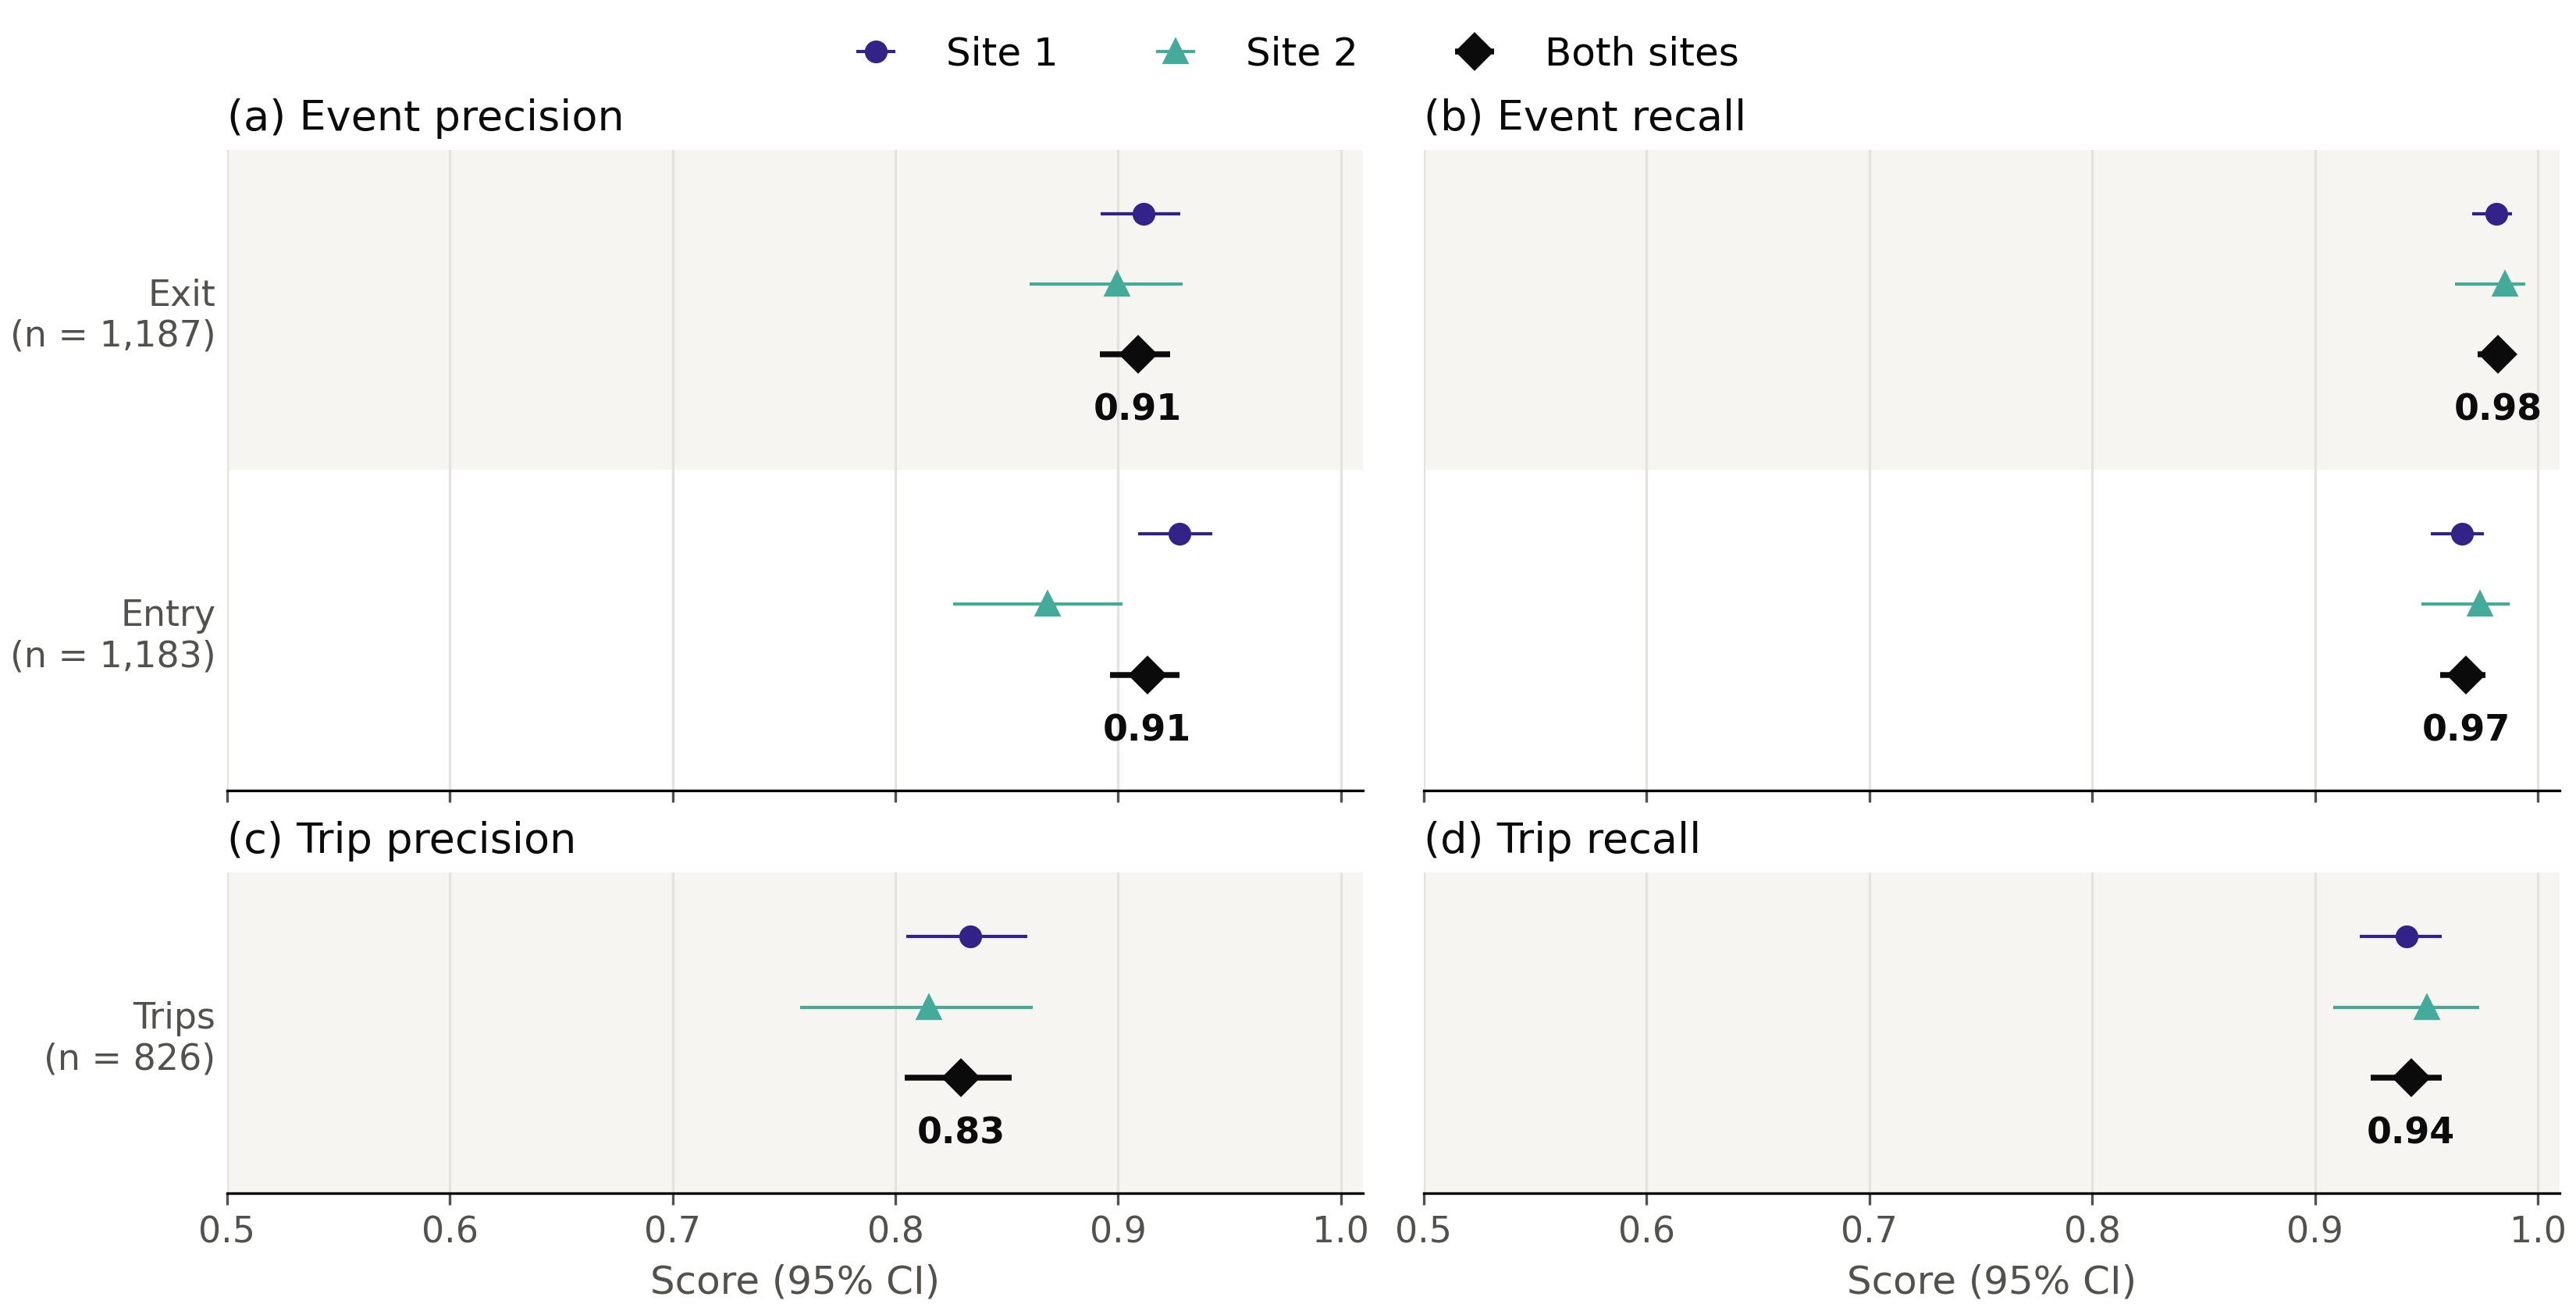

In [8]:
BAND = "#f6f5f2"
GROUP_STYLE = {
    "Site 1": dict(color=SITE_COLORS["mendels"], marker="o", mfc=SITE_COLORS["mendels"], ms=6, lw=1.0),
    "Site 2": dict(color=SITE_COLORS["natalies"], marker="^", mfc=SITE_COLORS["natalies"], ms=6.5, lw=1.0),
    "Both sites": dict(color=INK, marker="D", mfc=INK, ms=7.5, lw=1.8),
}
OFFSETS = {"Site 1": -0.3, "Site 2": -0.08, "Both sites": 0.14}


def panel(ax, d: pd.DataFrame, metric: str, title: str) -> None:
    d = d[d.metric == metric]
    cats = list(dict.fromkeys(d["category"]))
    for i in range(0, len(cats), 2):  # alternating row bands
        ax.axhspan(i - 0.5, i + 0.5, color=BAND, zorder=0, lw=0)
    for name, style in GROUP_STYLE.items():
        g = d[d.group == name].set_index("category").loc[cats]
        y = np.arange(len(cats)) + OFFSETS[name]
        ax.errorbar(g["value"], y, xerr=[g["value"] - g["lo"], g["hi"] - g["value"]],
                    ls="none", capsize=0, elinewidth=style["lw"], ms=style["ms"], marker=style["marker"],
                    color=style["color"], mfc=style["mfc"], mec=style["color"], label=name, zorder=3)
        if name == "Both sites":  # pooled value printed under its point
            for v, yi in zip(g["value"], y):
                ax.text(v, yi + 0.12, f"{v:.2f}", va="top", ha="center", fontsize=11, color=INK, fontweight="bold")
    ax.set_yticks(range(len(cats)), cats)
    ax.set_ylim(len(cats) - 0.5, -0.5)
    ax.set_xlim(0.5, 1.01)
    ax.set_xticks(np.arange(0.5, 1.01, 0.1))
    ax.set_title(title, loc="left", color=INK)
    ax.grid(axis="x", color="#e4e3df", lw=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(colors=MUTED)


apply_style()
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharex=True, sharey="row", constrained_layout=True,
                         gridspec_kw=dict(height_ratios=[2, 1]))
panel(axes[0, 0], ev, "Precision", "(a) Event precision")
panel(axes[0, 1], ev, "Recall", "(b) Event recall")
panel(axes[1, 0], tr, "Precision", "(c) Trip precision")
panel(axes[1, 1], tr, "Recall", "(d) Trip recall")
for ax in axes[1]:
    ax.set_xlabel("Score (95% CI)", color=MUTED)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=3, frameon=False)
save(fig, "fig_cv_evaluation")

## 4. Foraging trips and provisioned cells per nest tube

Each grid shows the 60 tubes as they sit in the hotel: the upper three rows are the top frame, the lower three the bottom frame, and columns A–J match tube positions.

- **Left:** foraging trips per tube.
- **Right:** shading shows provisioned cells; the label reads cells with larvae / provisioned cells. Blank tubes had no nest recorded.

Both sites share the same colour scales, so the two figures compare directly.

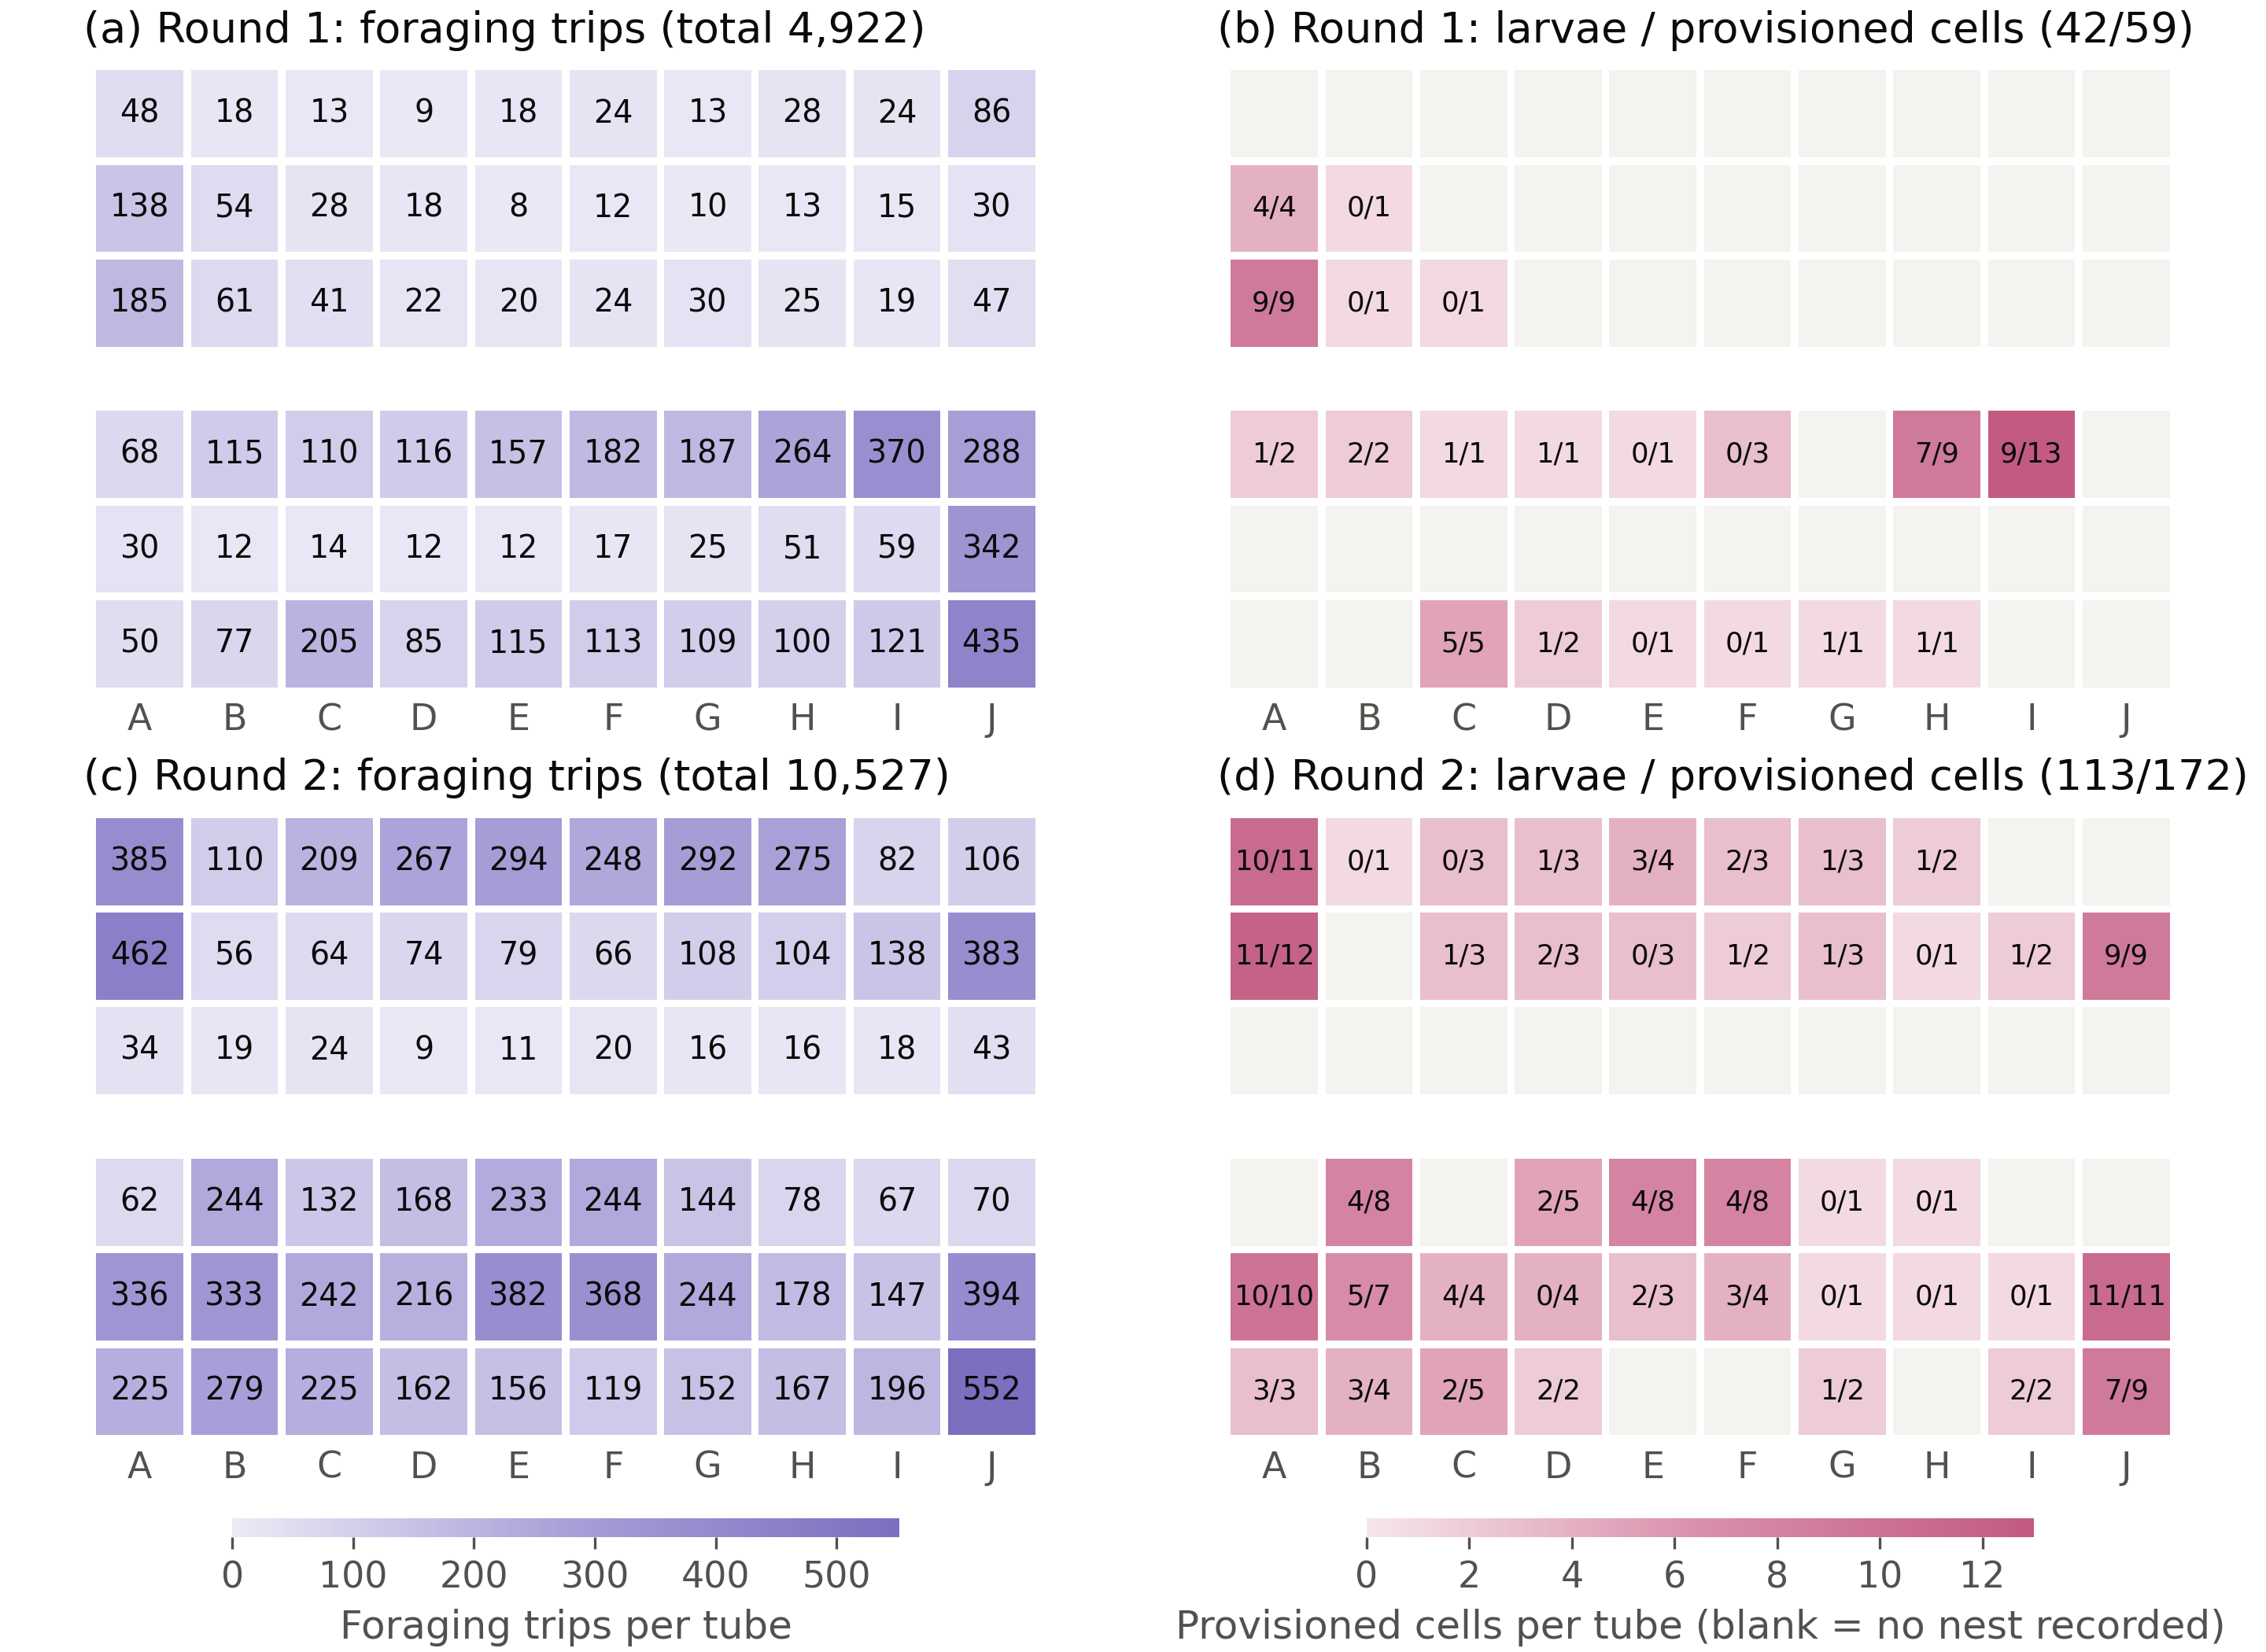

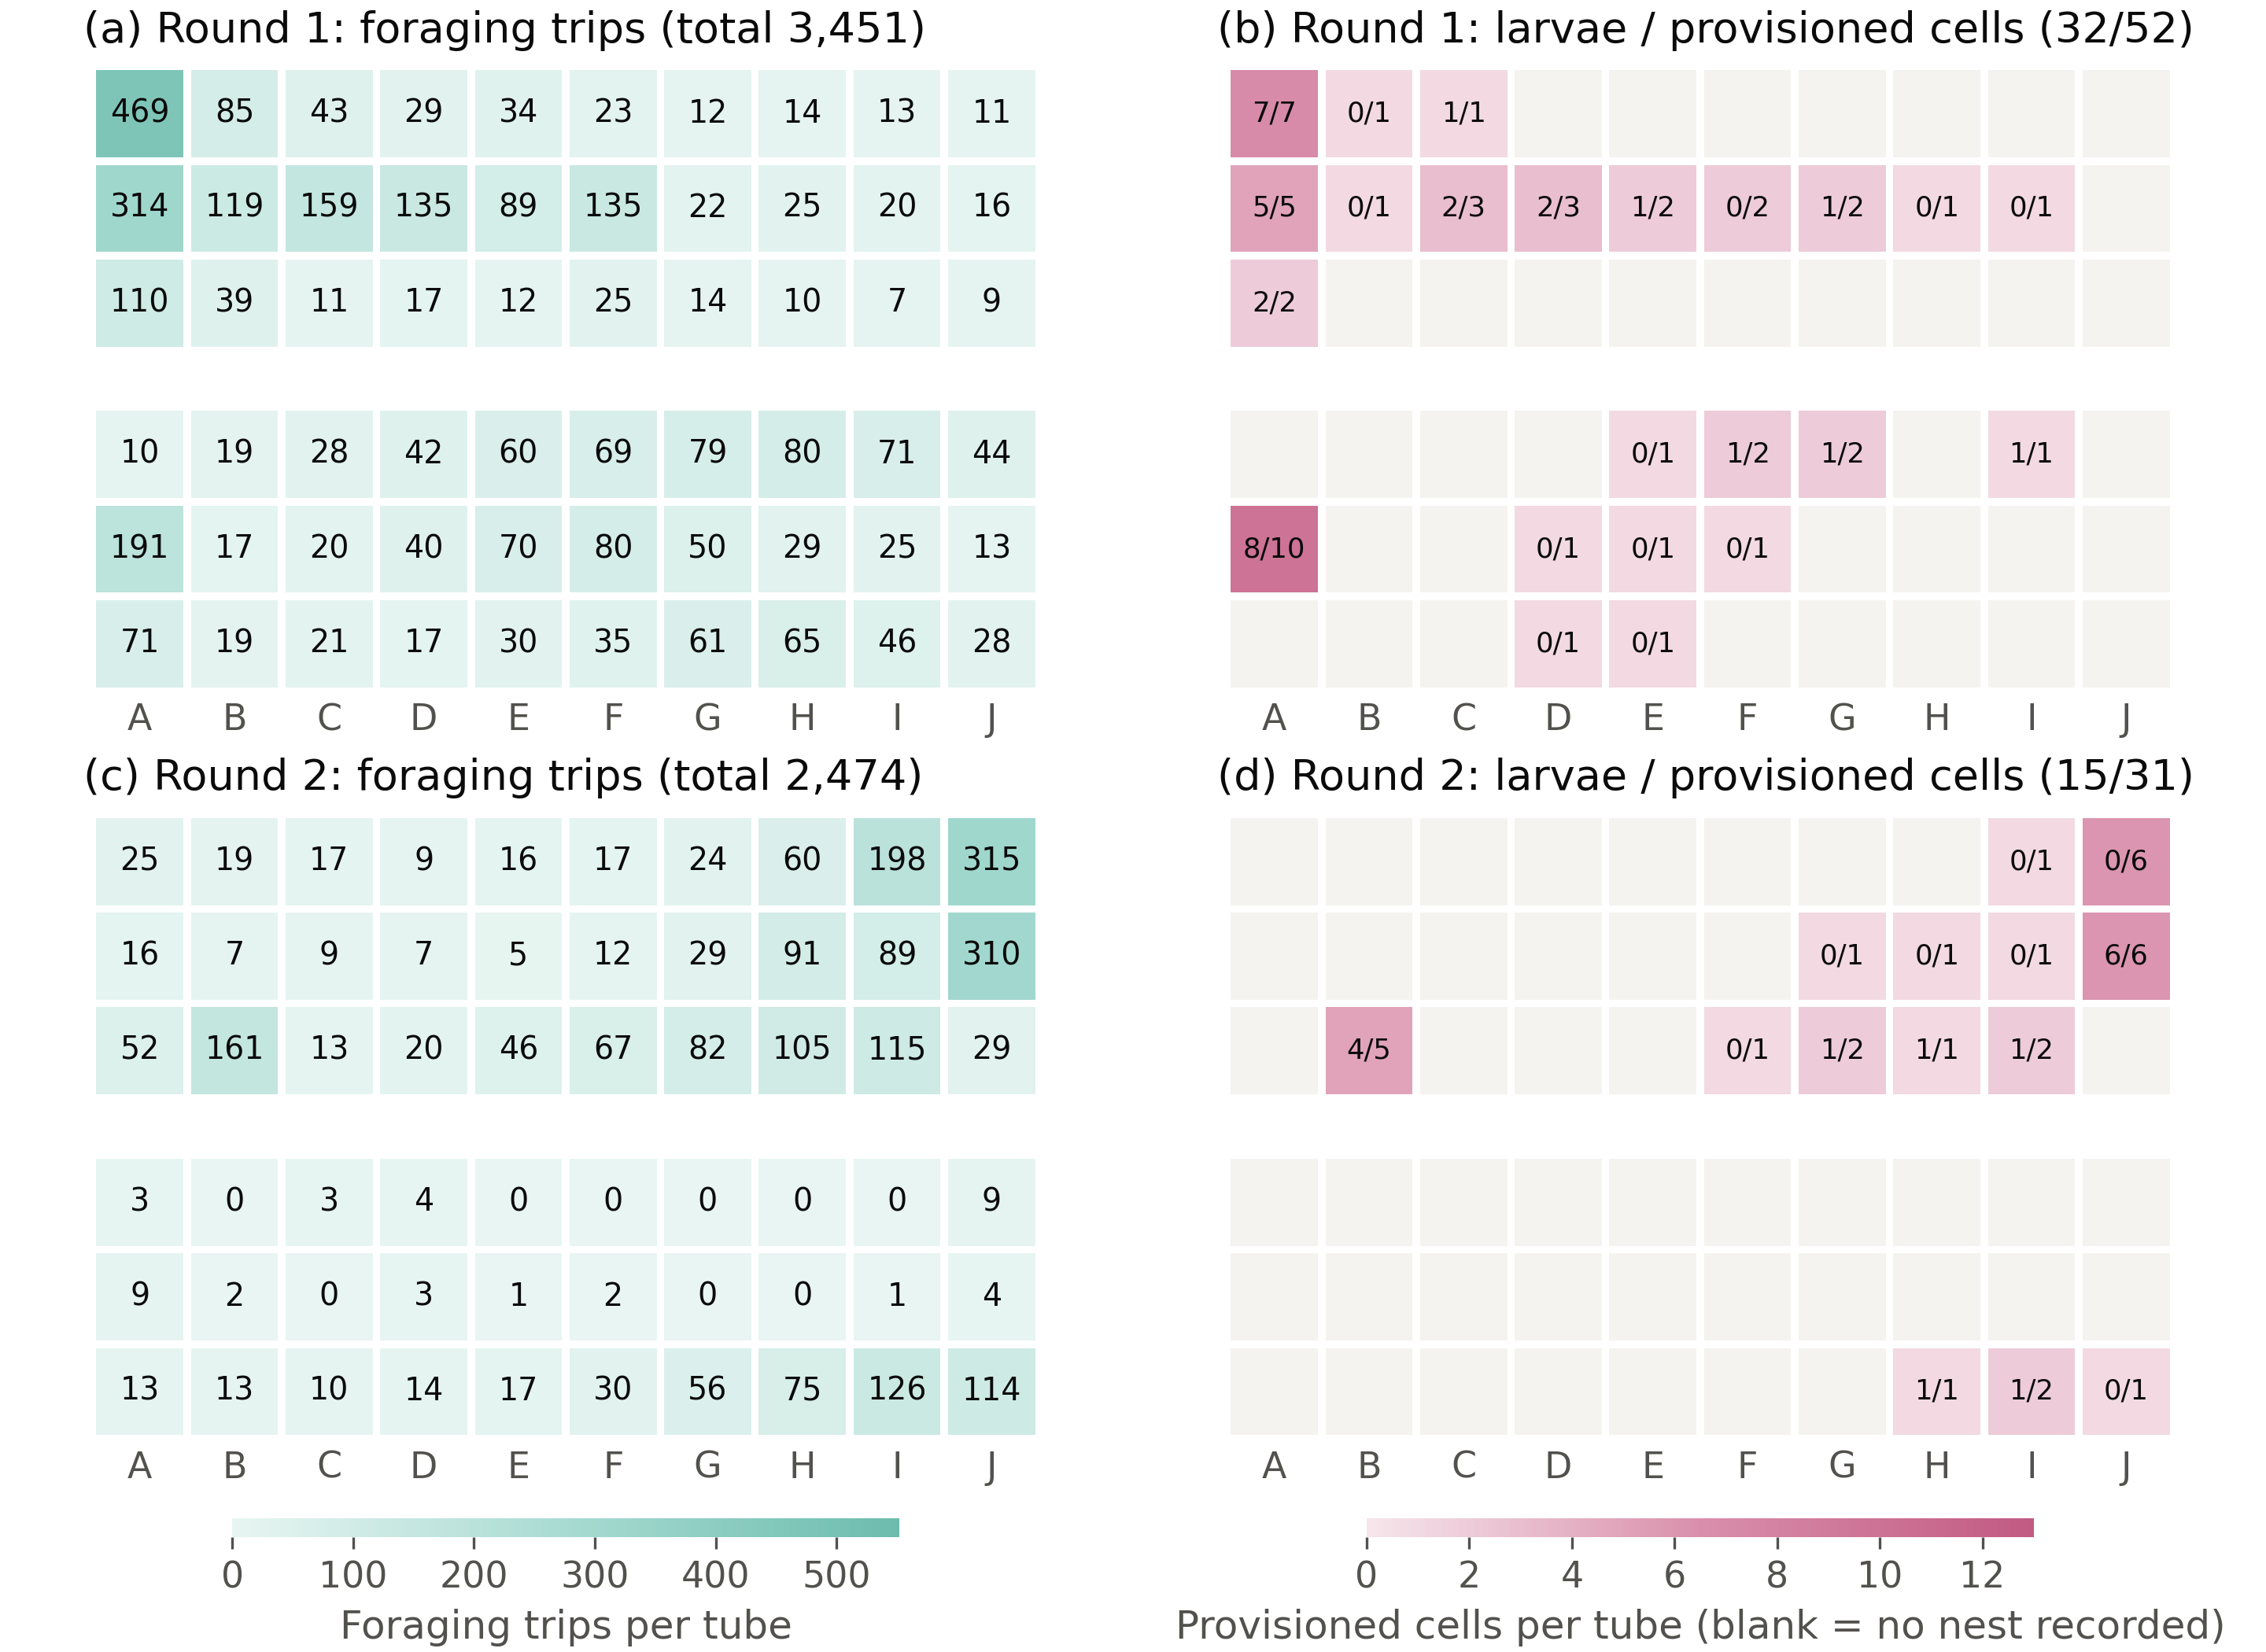

In [13]:
N_COLS = 10
NO_RECORD = "#f4f3f0"
CELL_CMAP = LinearSegmentedColormap.from_list("cells", ["#f6e6ec", "#d98fab", "#c25a82"])
TRIP_RAMPS = {"mendels": ["#eceaf6", "#a9a0d8", "#7b6fc0"], "natalies": ["#e8f5f2", "#a8dbd2", "#6cbcad"]}


def tube_xy(tube: np.ndarray):
    """Tube 1 top-left; rows of 10 (A-J); top frame rows 0-2, bottom frame rows 3-5 with a small gap."""
    row, col = (tube - 1) // N_COLS, (tube - 1) % N_COLS
    return col.astype(float), -(row + np.where(row >= 3, 0.6, 0.0))


def tube_values(rnd: int, pattern: str) -> pd.DataFrame:
    """Trips and matching cells per tube for one round; cells stay NaN where no nest was recorded."""
    keys = ["site_name", "tube"]
    t = trips[trips["release"] == rnd].groupby(keys).size().rename("trips")
    n = nests[nests["release"] == rnd]
    cells = n.assign(hit=n["provision"].str.contains(pattern, na=False)).groupby(keys)["hit"].sum().rename("cells")
    every_tube = pd.MultiIndex.from_product([sorted(SITE_LABELS), range(1, 61)], names=keys)
    return pd.concat([t, cells], axis=1).reindex(every_tube).fillna({"trips": 0}).reset_index()


def draw_grid(ax, values, cmap, vmax, fontsize=9.5, labels=None) -> None:
    x, y = tube_xy(np.arange(1, 61))
    labels = labels if labels is not None else [f"{v:.0f}" for v in values]
    for xi, yi, v, lab in zip(x, y, values, labels):
        missing = np.isnan(v)
        ax.add_patch(plt.Rectangle((xi - 0.46, yi - 0.46), 0.92, 0.92, lw=0,
                                   facecolor=NO_RECORD if missing else cmap(v / vmax)))
        ax.text(xi, yi, "" if missing else lab, ha="center", va="center", fontsize=fontsize, color=INK)
    ax.set_xlim(-0.6, N_COLS - 0.4)
    ax.set_ylim(-6.1, 0.55)
    ax.set_aspect("equal")
    ax.set_xticks(range(N_COLS), list("ABCDEFGHIJ"))
    ax.set_yticks([])
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)


tube_data = {}
for site in SITE_LABELS:
    for rnd in (1, 2):
        d = tube_values(rnd, PROVISIONED).rename(columns={"cells": "provisioned"})
        d["larvae"] = tube_values(rnd, LARVAE)["cells"].to_numpy()
        tube_data[(site, rnd)] = d
vmax = {c: max(d[c].max() for d in tube_data.values()) for c in ("trips", "provisioned")}


def plot_site(site: str, name: str) -> None:
    apply_style()
    panels = [("trips", "foraging trips", LinearSegmentedColormap.from_list("trips", TRIP_RAMPS[site])),
              ("provisioned", "provisioned cells", CELL_CMAP)]
    fig, axes = plt.subplots(2, 2, figsize=(9.6, 7.0), constrained_layout=True)
    letters = iter("abcd")
    for row, rnd in enumerate((1, 2)):
        s = tube_data[(site, rnd)].query("site_name == @site").sort_values("tube")
        for col, (column, label, cmap) in enumerate(panels):
            ax = axes[row, col]
            values = s[column].to_numpy(dtype=float)
            if column == "provisioned":
                labs = [f"{l:.0f}/{v:.0f}" if v == v else "" for l, v in zip(s["larvae"], values)]
                draw_grid(ax, values, cmap, vmax[column], fontsize=8.5, labels=labs)
                title = f"larvae / provisioned cells ({int(s['larvae'].sum())}/{int(np.nansum(values))})"
            else:
                draw_grid(ax, values, cmap, vmax[column])
                title = f"{label} (total {int(s[column].sum()):,})"
            ax.set_title(f"({next(letters)}) Round {rnd}: {title}")
    for col, (column, label, cmap) in enumerate(panels):
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, vmax[column]))
        cb = fig.colorbar(sm, ax=axes[:, col], orientation="horizontal", shrink=0.6, aspect=35, pad=0.02)
        cb.set_label(f"{label.capitalize()} per tube" + (" (blank = no nest recorded)" if column == "provisioned" else ""),
                     color=MUTED)
        cb.outline.set_visible(False)
        cb.set_ticks(range(0, int(vmax[column]) + 1, 2 if column == "provisioned" else 100))
    save(fig, name)


plot_site("mendels", "fig_tube_maps_site1")
plot_site("natalies", "fig_tube_maps_site2")

## 5. Daily foraging trips and land cover

Land cover within a 1-mile radius of each site (from BeeShiny); daily foraging trips, with days that have less than 1 h of video shaded grey. The dashed line marks the nest swap.

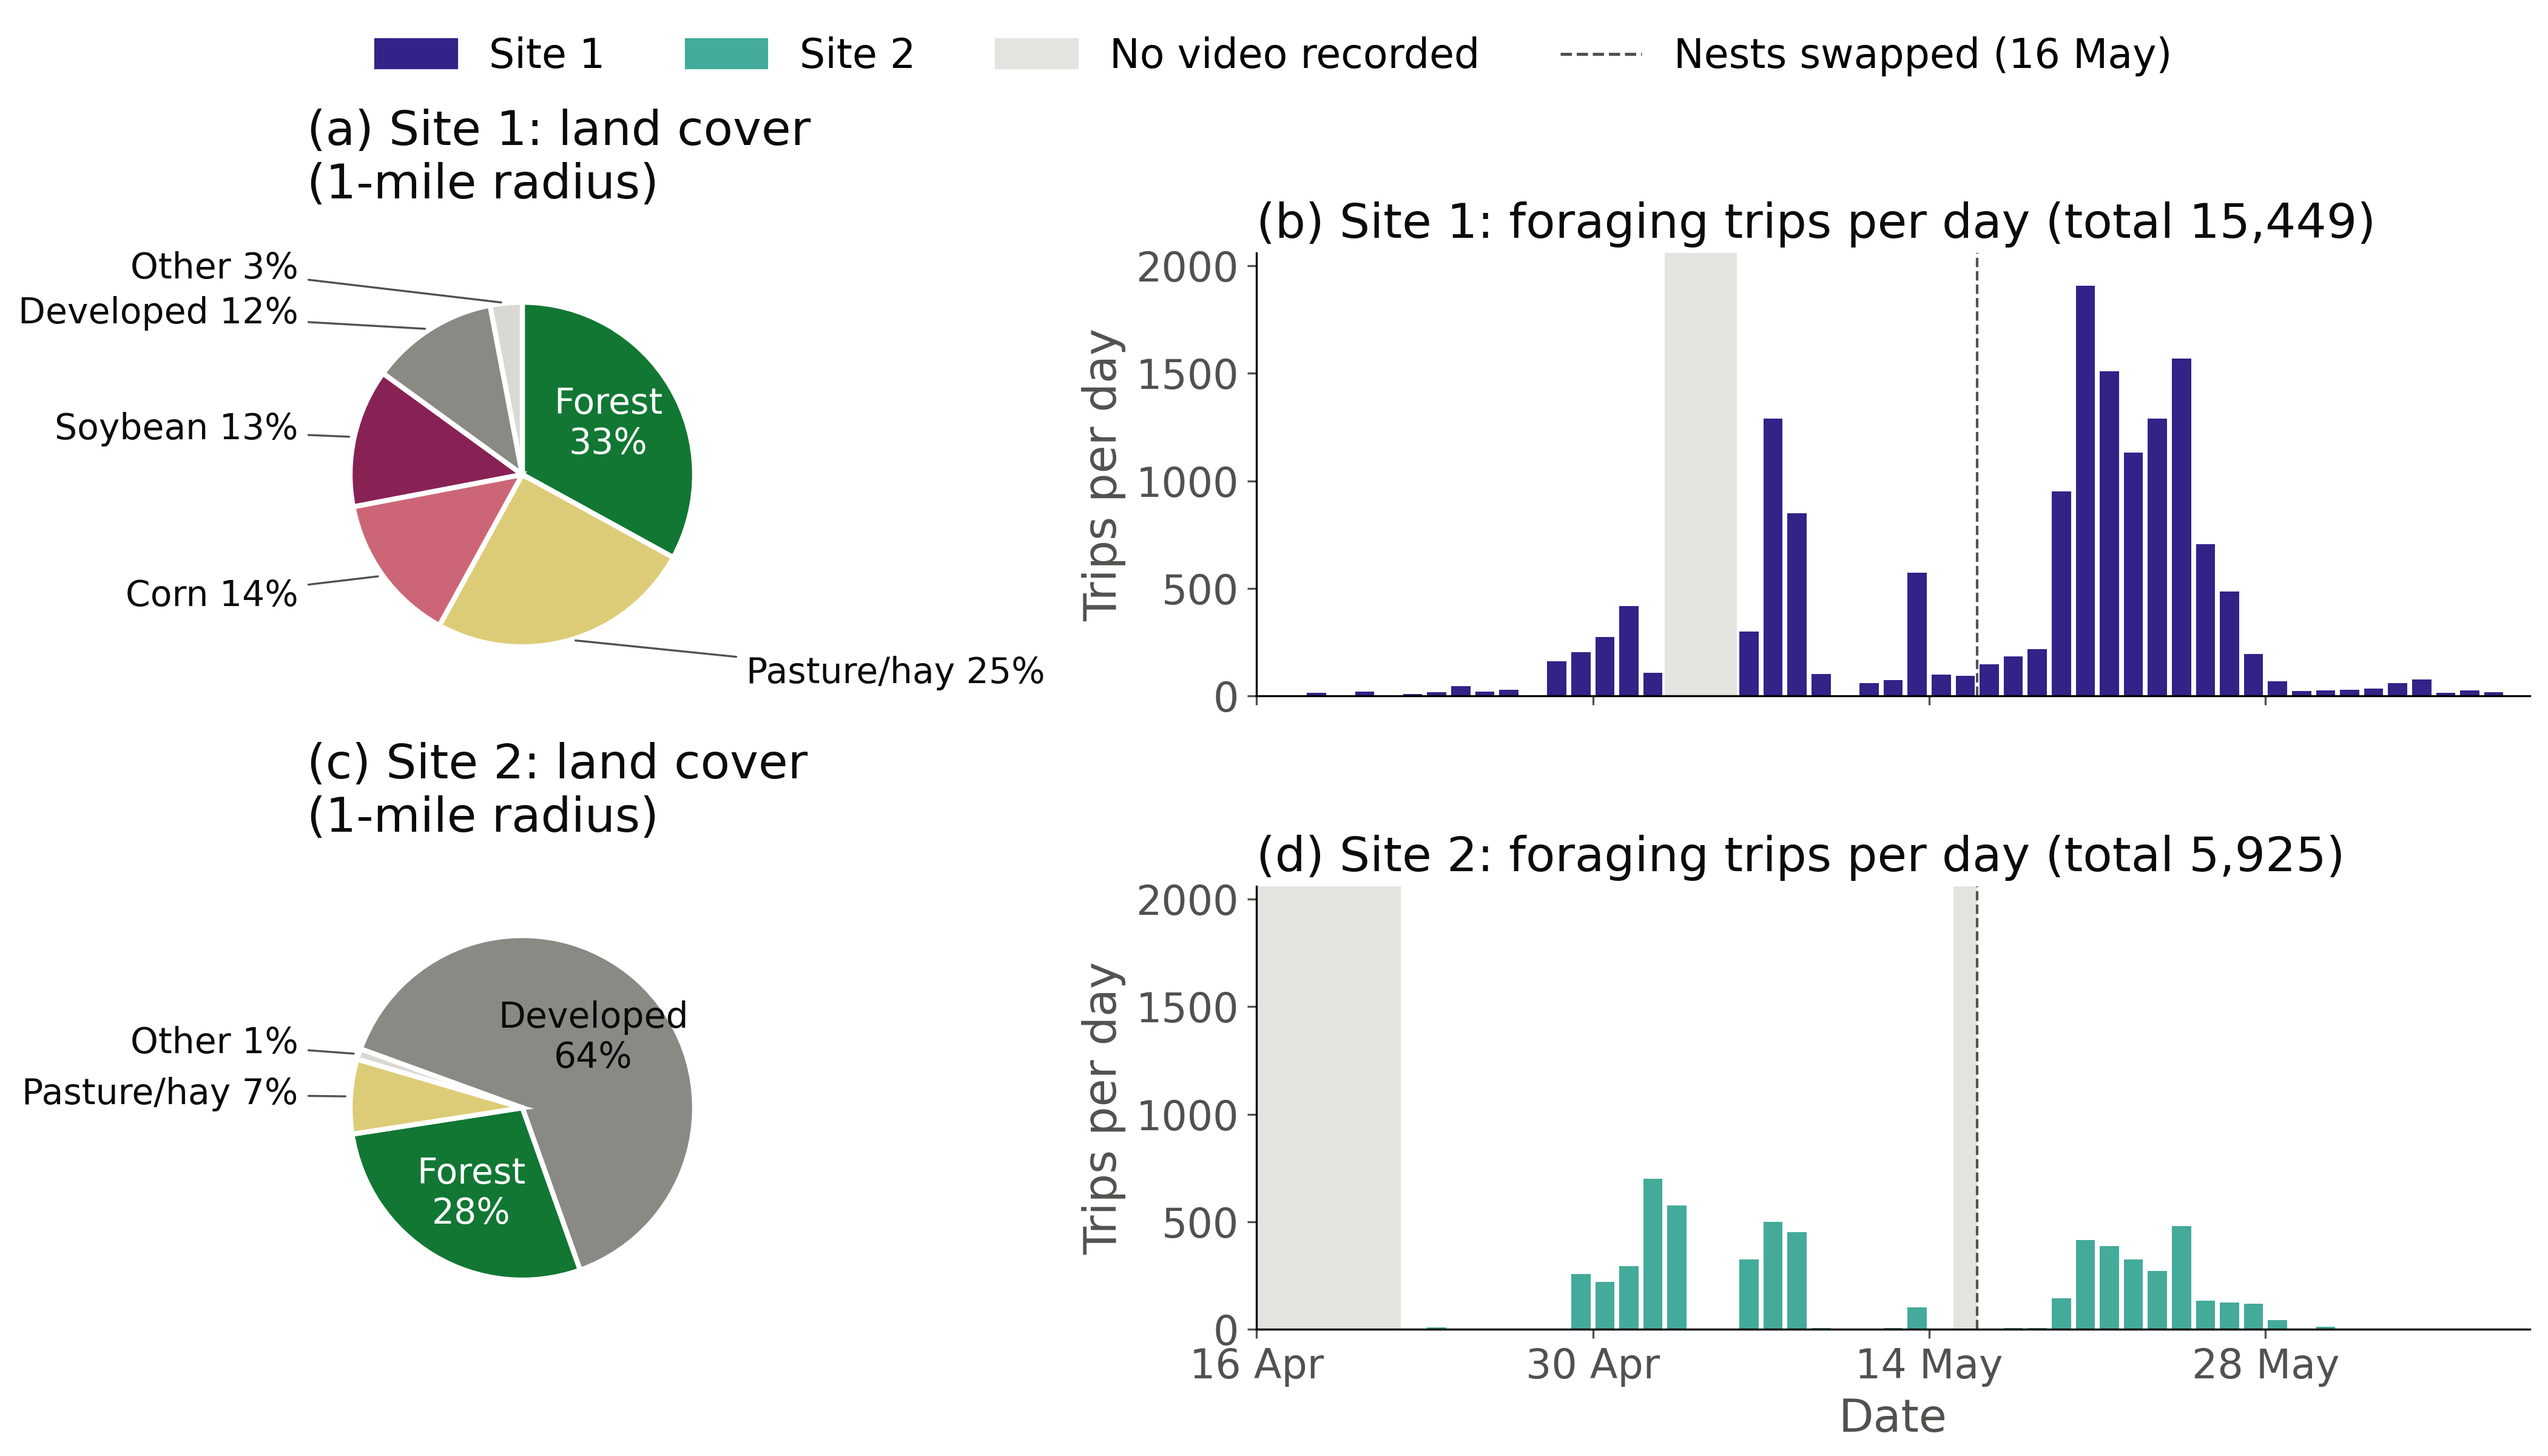

In [16]:
LANDSCAPE = {
    "Site 1": {"Forest": 33, "Pasture/hay": 25, "Corn": 14, "Soybean": 13, "Developed": 12},
    "Site 2": {"Developed": 64, "Forest": 28, "Pasture/hay": 7},
}  # % of area; "Other" = remainder to 100
# The land cover data are from USDA Cropland Data Layer (CDL) and were extracted from the Beescape platform for a 1-mile radius around each site.
DARK_SLICES = {"Forest", "Soybean"}  # white text for contrast
INSIDE_MIN_PCT = 26  # smaller slices are labelled outside with a leader line
NO_VIDEO = "#e4e3df"


def draw_pie(ax, site: str, fontsize: int = 11) -> None:
    cover = dict(sorted(LANDSCAPE[site].items(), key=lambda kv: -kv[1]))
    if (other := 100 - sum(cover.values())) > 0:
        cover["Other"] = other
    wedges, _ = ax.pie(cover.values(), colors=[LANDCOVER_COLORS[k] for k in cover],
                       startangle=90 if site == "Site 1" else 160, counterclock=False,
                       wedgeprops=dict(edgecolor="white", linewidth=2))
    outside = []
    for w, (name, pct) in zip(wedges, cover.items()):
        ang = np.deg2rad((w.theta2 + w.theta1) / 2)
        x, y = np.cos(ang), np.sin(ang)
        if pct >= INSIDE_MIN_PCT:
            ax.text(0.58 * x, 0.58 * y, f"{name}\n{pct}%", ha="center", va="center", fontsize=fontsize,
                    color="white" if name in DARK_SLICES else INK)
        else:
            outside.append([x, y, f"{name} {pct}%"])
    for side in (1, -1):  # space labels on each side so they never touch
        labels = sorted([o for o in outside if np.sign(o[0]) == side or (o[0] == 0 and side == 1)], key=lambda o: -o[1])
        last = None
        for x, y, text in labels:
            ty = 1.2 * y if last is None else min(1.2 * y, last - 0.26)
            last = ty
            ax.annotate(text, xy=(x, y), xytext=(1.3 * side, ty), ha="left" if side > 0 else "right", va="center",
                        fontsize=fontsize, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
    ax.set_aspect("equal")


def no_video_days(site: str, days: pd.DatetimeIndex) -> pd.DatetimeIndex:
    f = files[files["run_status"].eq("completed") & files["site_name"].eq(site)]
    recorded = pd.to_datetime(f["date"]).unique()
    return days[~days.isin(recorded)]


plt.rcParams.update({"font.size": 18, "axes.titlesize": 19, "axes.labelsize": 18,  # sized for a 14-in figure
                     "xtick.labelsize": 16, "ytick.labelsize": 16, "legend.fontsize": 16})
days = pd.date_range(files["date"].min(), files["date"].max(), freq="D")  # first to last recording day
counts = trips.groupby(["site_name", trips["exit_time"].dt.normalize()]).size()

fig = plt.figure(figsize=(14, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 2, width_ratios=[1.15, 3.4])
fig.get_layout_engine().set(h_pad=0.08, w_pad=0.1)
first = fig.add_subplot(gs[0, 1])
bar_axes = [first, fig.add_subplot(gs[1, 1], sharex=first)]
bar_axes[1].sharey(bar_axes[0])
pie_axes = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])]
for ax, pie_ax, site, (lp, ld) in zip(bar_axes, pie_axes, ["mendels", "natalies"], [("a", "b"), ("c", "d")]):
    draw_pie(pie_ax, SITE_LABELS[site], fontsize=14)
    pie_ax.set_title(f"({lp}) {SITE_LABELS[site]}: land cover\n(1-mile radius)", loc="left", color=INK, pad=24)
    for gap in no_video_days(site, days):
        ax.axvspan(gap, gap + pd.Timedelta(days=1), color=NO_VIDEO, lw=0, zorder=0)
    n = counts.get(site, pd.Series(dtype=float)).reindex(days, fill_value=0)
    ax.bar(days + pd.Timedelta(hours=12), n, width=0.8, color=SITE_COLORS[site])
    ax.axvline(SWAP_DATE, color=MUTED, ls="--", lw=1)
    ax.set_ylim(0, counts.max() * 1.08)
    ax.set_title(f"({ld}) {SITE_LABELS[site]}: foraging trips per day (total {int(n.sum()):,})", loc="left", color=INK)
    ax.set_ylabel("Trips per day", color=MUTED)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
key = [plt.Rectangle((0, 0), 1, 1, color=SITE_COLORS[s], label=SITE_LABELS[s]) for s in ["mendels", "natalies"]]
key += [plt.Rectangle((0, 0), 1, 1, color=NO_VIDEO, label="No video recorded"),
        plt.Line2D([], [], color=MUTED, ls="--", lw=1.2, label="Nests swapped (16 May)")]
fig.legend(handles=key, loc="outside upper center", ncol=len(key), frameon=False)
bar_axes[0].tick_params(labelbottom=False)
bar_axes[1].set_xticks(pd.date_range(days[0], days[-1], freq="14D"))
bar_axes[1].set_xlim(days[0], days[-1] + pd.Timedelta(days=1))
bar_axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
bar_axes[1].set_xlabel("Date", color=MUTED)
save(fig, "fig_daily_trips_landcover")

## 6. Foraging trips vs provisioned cells

One point per tube-round with a nest record (a recorded tube with no detected trips counts as 0 trips). Colour shows the site and marker the round; points are jittered slightly upward or downward so overlapping tubes stay visible.

The line is a single least-squares regression across both sites and rounds, and the shaded band is its 95% confidence interval. 

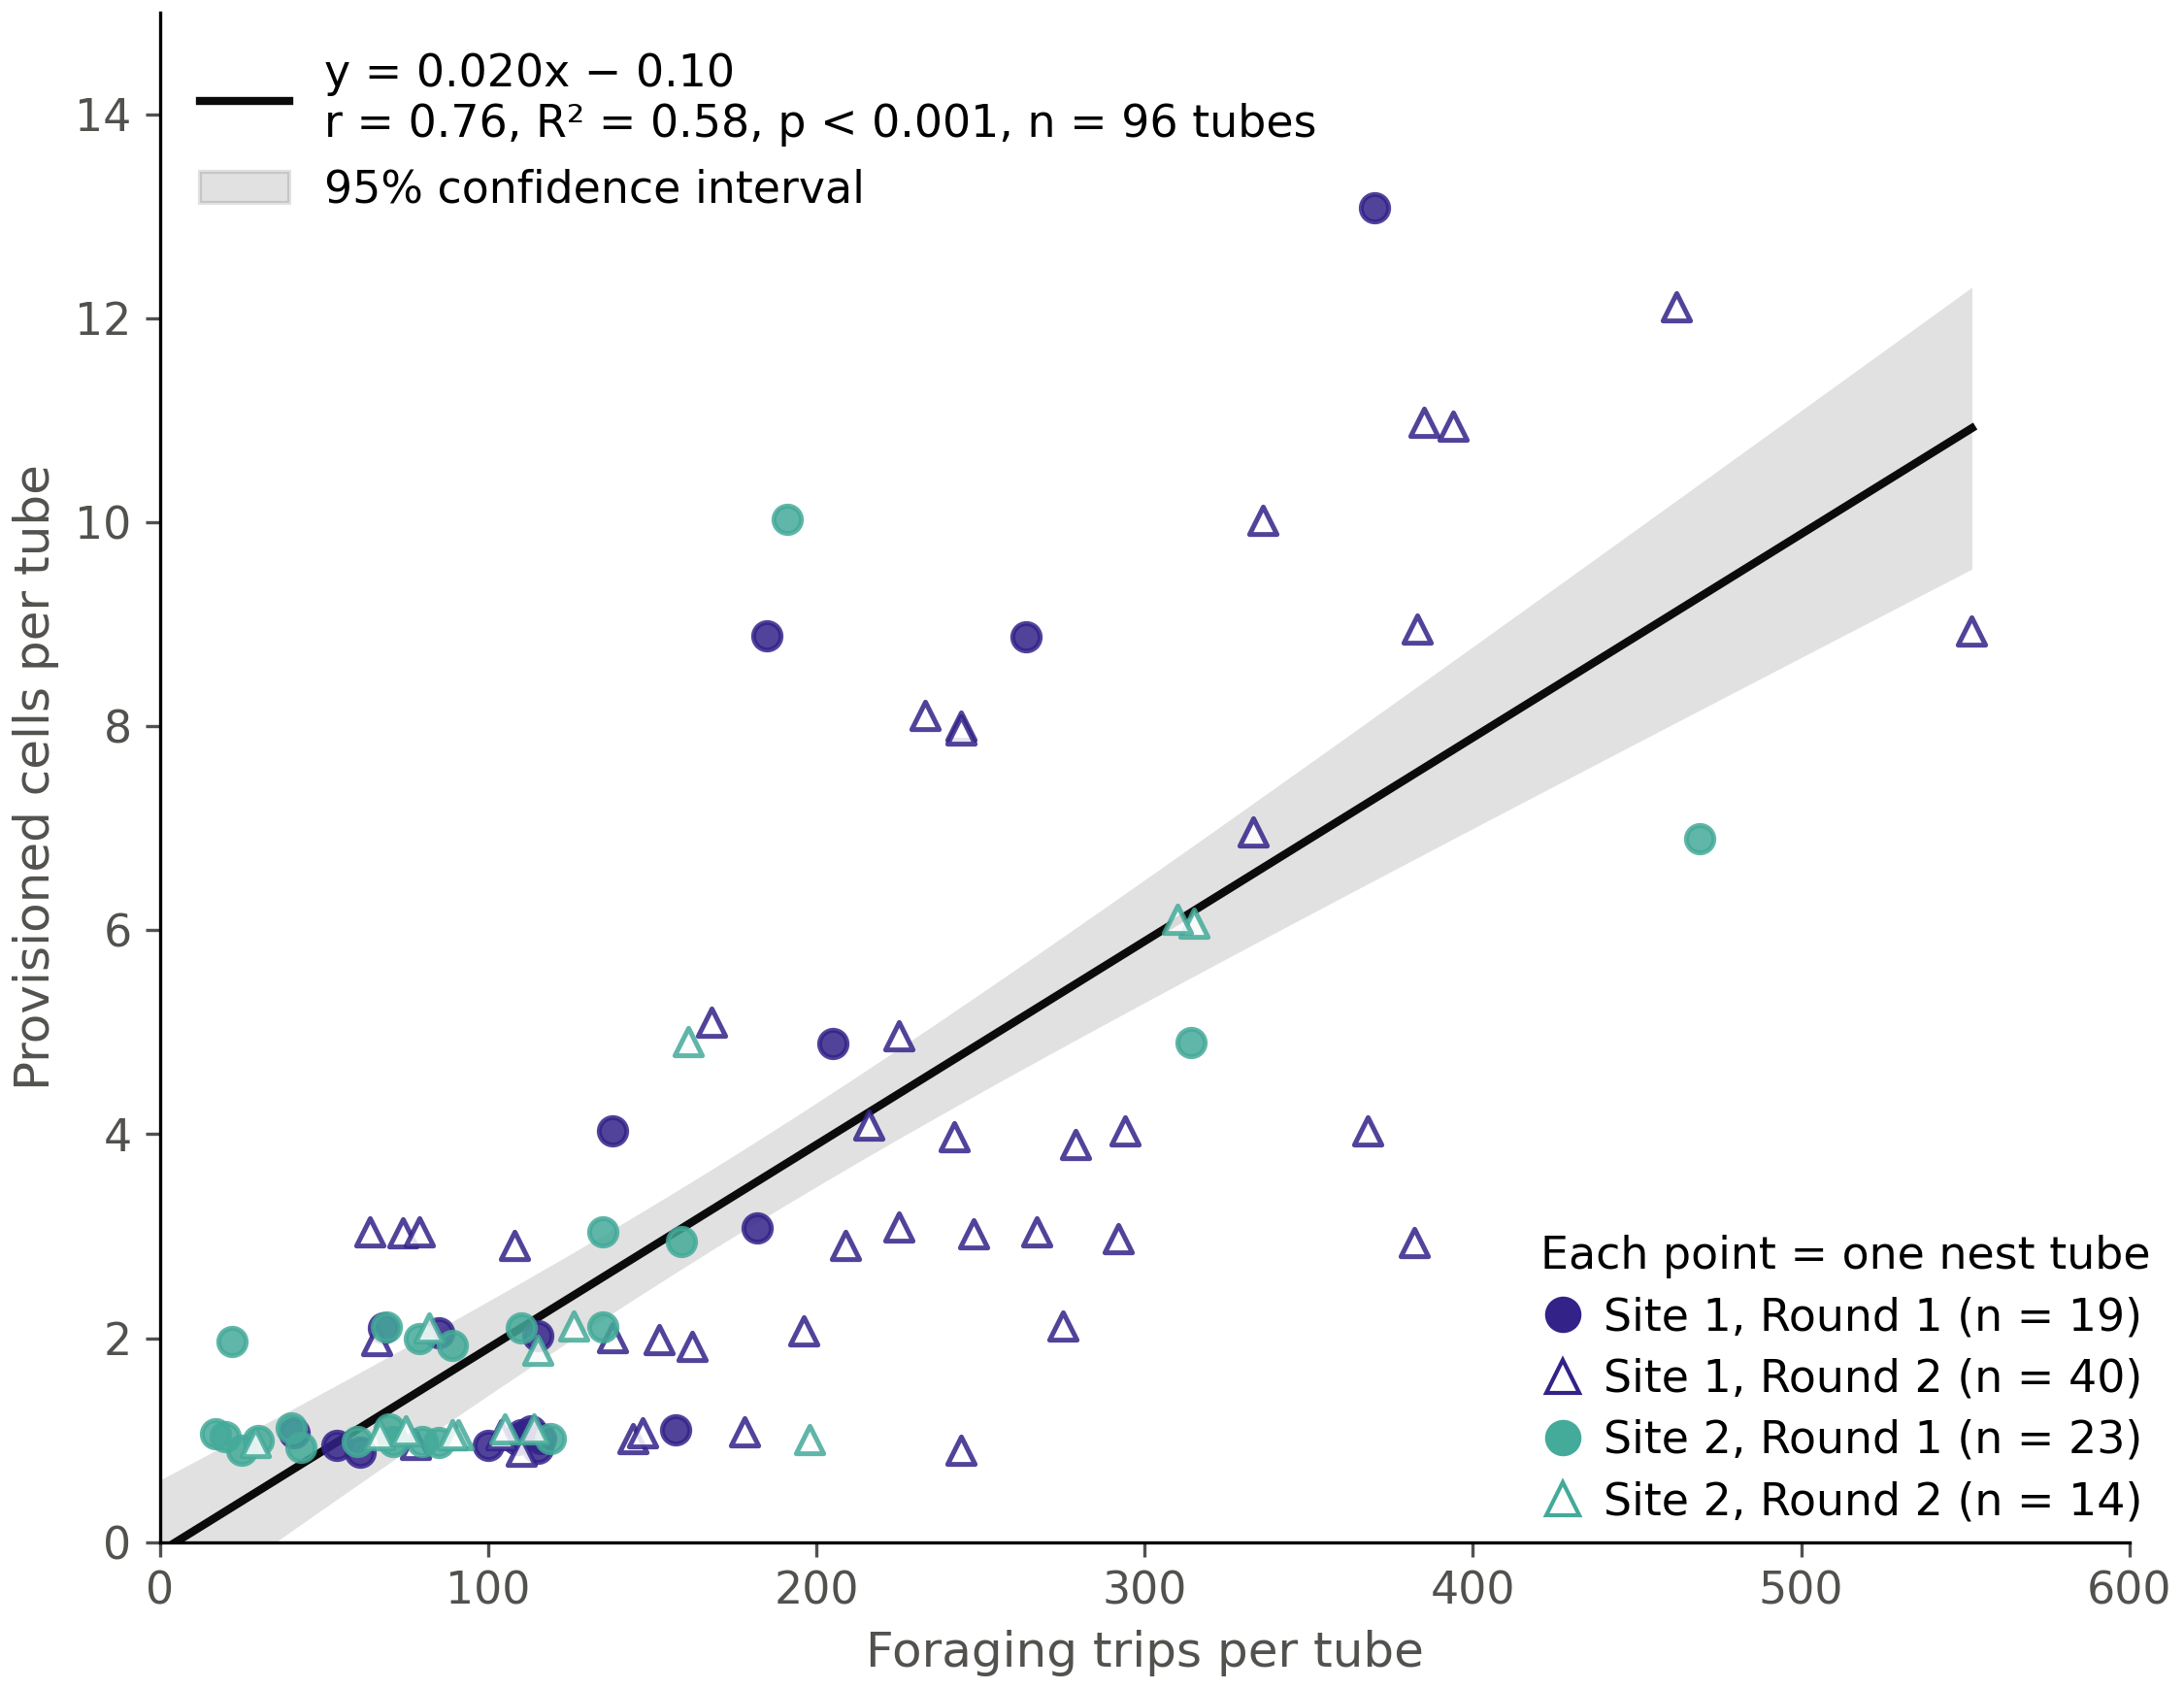

n            96.0000
r             0.7638
R2            0.5834
slope         0.0200
intercept    -0.0968
p             0.0000
dtype: float64

In [ ]:
keys = ["release", "site_name", "tube"]
per_tube = (nests.assign(prov=nests["provision"].str.contains(PROVISIONED, na=False))
            .groupby(keys).agg(provisioned=("prov", "sum")))
reg = per_tube.join(trips.groupby(keys).size().rename("trips")).fillna({"trips": 0}).reset_index()
fit = linregress(reg["trips"], reg["provisioned"])


def fmt_p(p: float) -> str:
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


apply_style()
fig, ax = plt.subplots(figsize=(7.5, 5.8), constrained_layout=True)
rng = np.random.default_rng(0)
handles = []
for site in sorted(SITE_LABELS):
    c = SITE_COLORS[site]
    for rel, style in ROUND_STYLE.items():
        g = reg[(reg.site_name == site) & (reg.release == rel)]
        y = g["provisioned"] + rng.uniform(-0.12, 0.12, len(g))
        ax.scatter(g["trips"], y, s=46, marker=style["marker"], lw=1.2, zorder=3,
                   facecolors=c if style["filled"] else "white", edgecolors=c, alpha=0.85)
        handles.append(plt.Line2D([], [], ls="", marker=style["marker"], ms=8, mec=c,
                                  mfc=c if style["filled"] else "white",
                                  label=f"{SITE_LABELS[site]}, Round {rel} (n = {len(g)})"))
xs = np.linspace(0, reg["trips"].max(), 50)
x, n = reg["trips"].to_numpy(), len(reg)
resid = reg["provisioned"].to_numpy() - (fit.intercept + fit.slope * x)
se_fit = np.sqrt(resid @ resid / (n - 2)) * np.sqrt(1 / n + (xs - x.mean()) ** 2 / ((x - x.mean()) ** 2).sum())
half = t_dist.ppf(0.975, n - 2) * se_fit  # 95% CI of the fitted line
line = fit.intercept + fit.slope * xs
ax.fill_between(xs, line - half, line + half, color=INK, alpha=0.12, lw=0, zorder=1)
ax.plot(xs, line, color=INK, lw=2, zorder=2)
sign = "+" if fit.intercept >= 0 else "−"
fit_key = [plt.Line2D([], [], color=INK, lw=2,
                      label=f"y = {fit.slope:.3f}x {sign} {abs(fit.intercept):.2f}\n"
                            f"r = {fit.rvalue:.2f}, R² = {fit.rvalue ** 2:.2f}, {fmt_p(fit.pvalue)}, n = {n} tubes"),
           plt.Rectangle((0, 0), 1, 1, color=INK, alpha=0.12, label="95% confidence interval")]
ax.add_artist(ax.legend(handles=fit_key, frameon=False, loc="upper left", fontsize=11))

ax.legend(handles=handles, frameon=False, loc="lower right", fontsize=11, title="Each point = one nest tube",
          title_fontsize=11, alignment="left", bbox_to_anchor=(1.02, 0.0),
          handlelength=1, handletextpad=0.4, borderaxespad=0, labelspacing=0.4)

ax.set_xlabel("Foraging trips per tube", color=MUTED)
ax.set_ylabel("Provisioned cells per tube", color=MUTED)
ax.set_ylim(0, 15)
ax.set_yticks(range(0, 15, 2))
ax.set_xlim(0, np.ceil(reg["trips"].max() / 100) * 100)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
save(fig, "fig_trips_vs_provisioned_cells", width=700)

pd.Series(dict(n=n, r=fit.rvalue, R2=fit.rvalue ** 2, slope=fit.slope, intercept=fit.intercept, p=fit.pvalue)).round(4)

## 7. Trip duration between sites

Repeated trips from one nest are not independent, so each tube-round with at least one provisioned cell contributes one value: **the median duration of its trips**. Sites are compared with a two-sided Mann–Whitney U test. z includes a correction for ties, and the effect size is r = |z| / √N. Bars are 1-min bins.

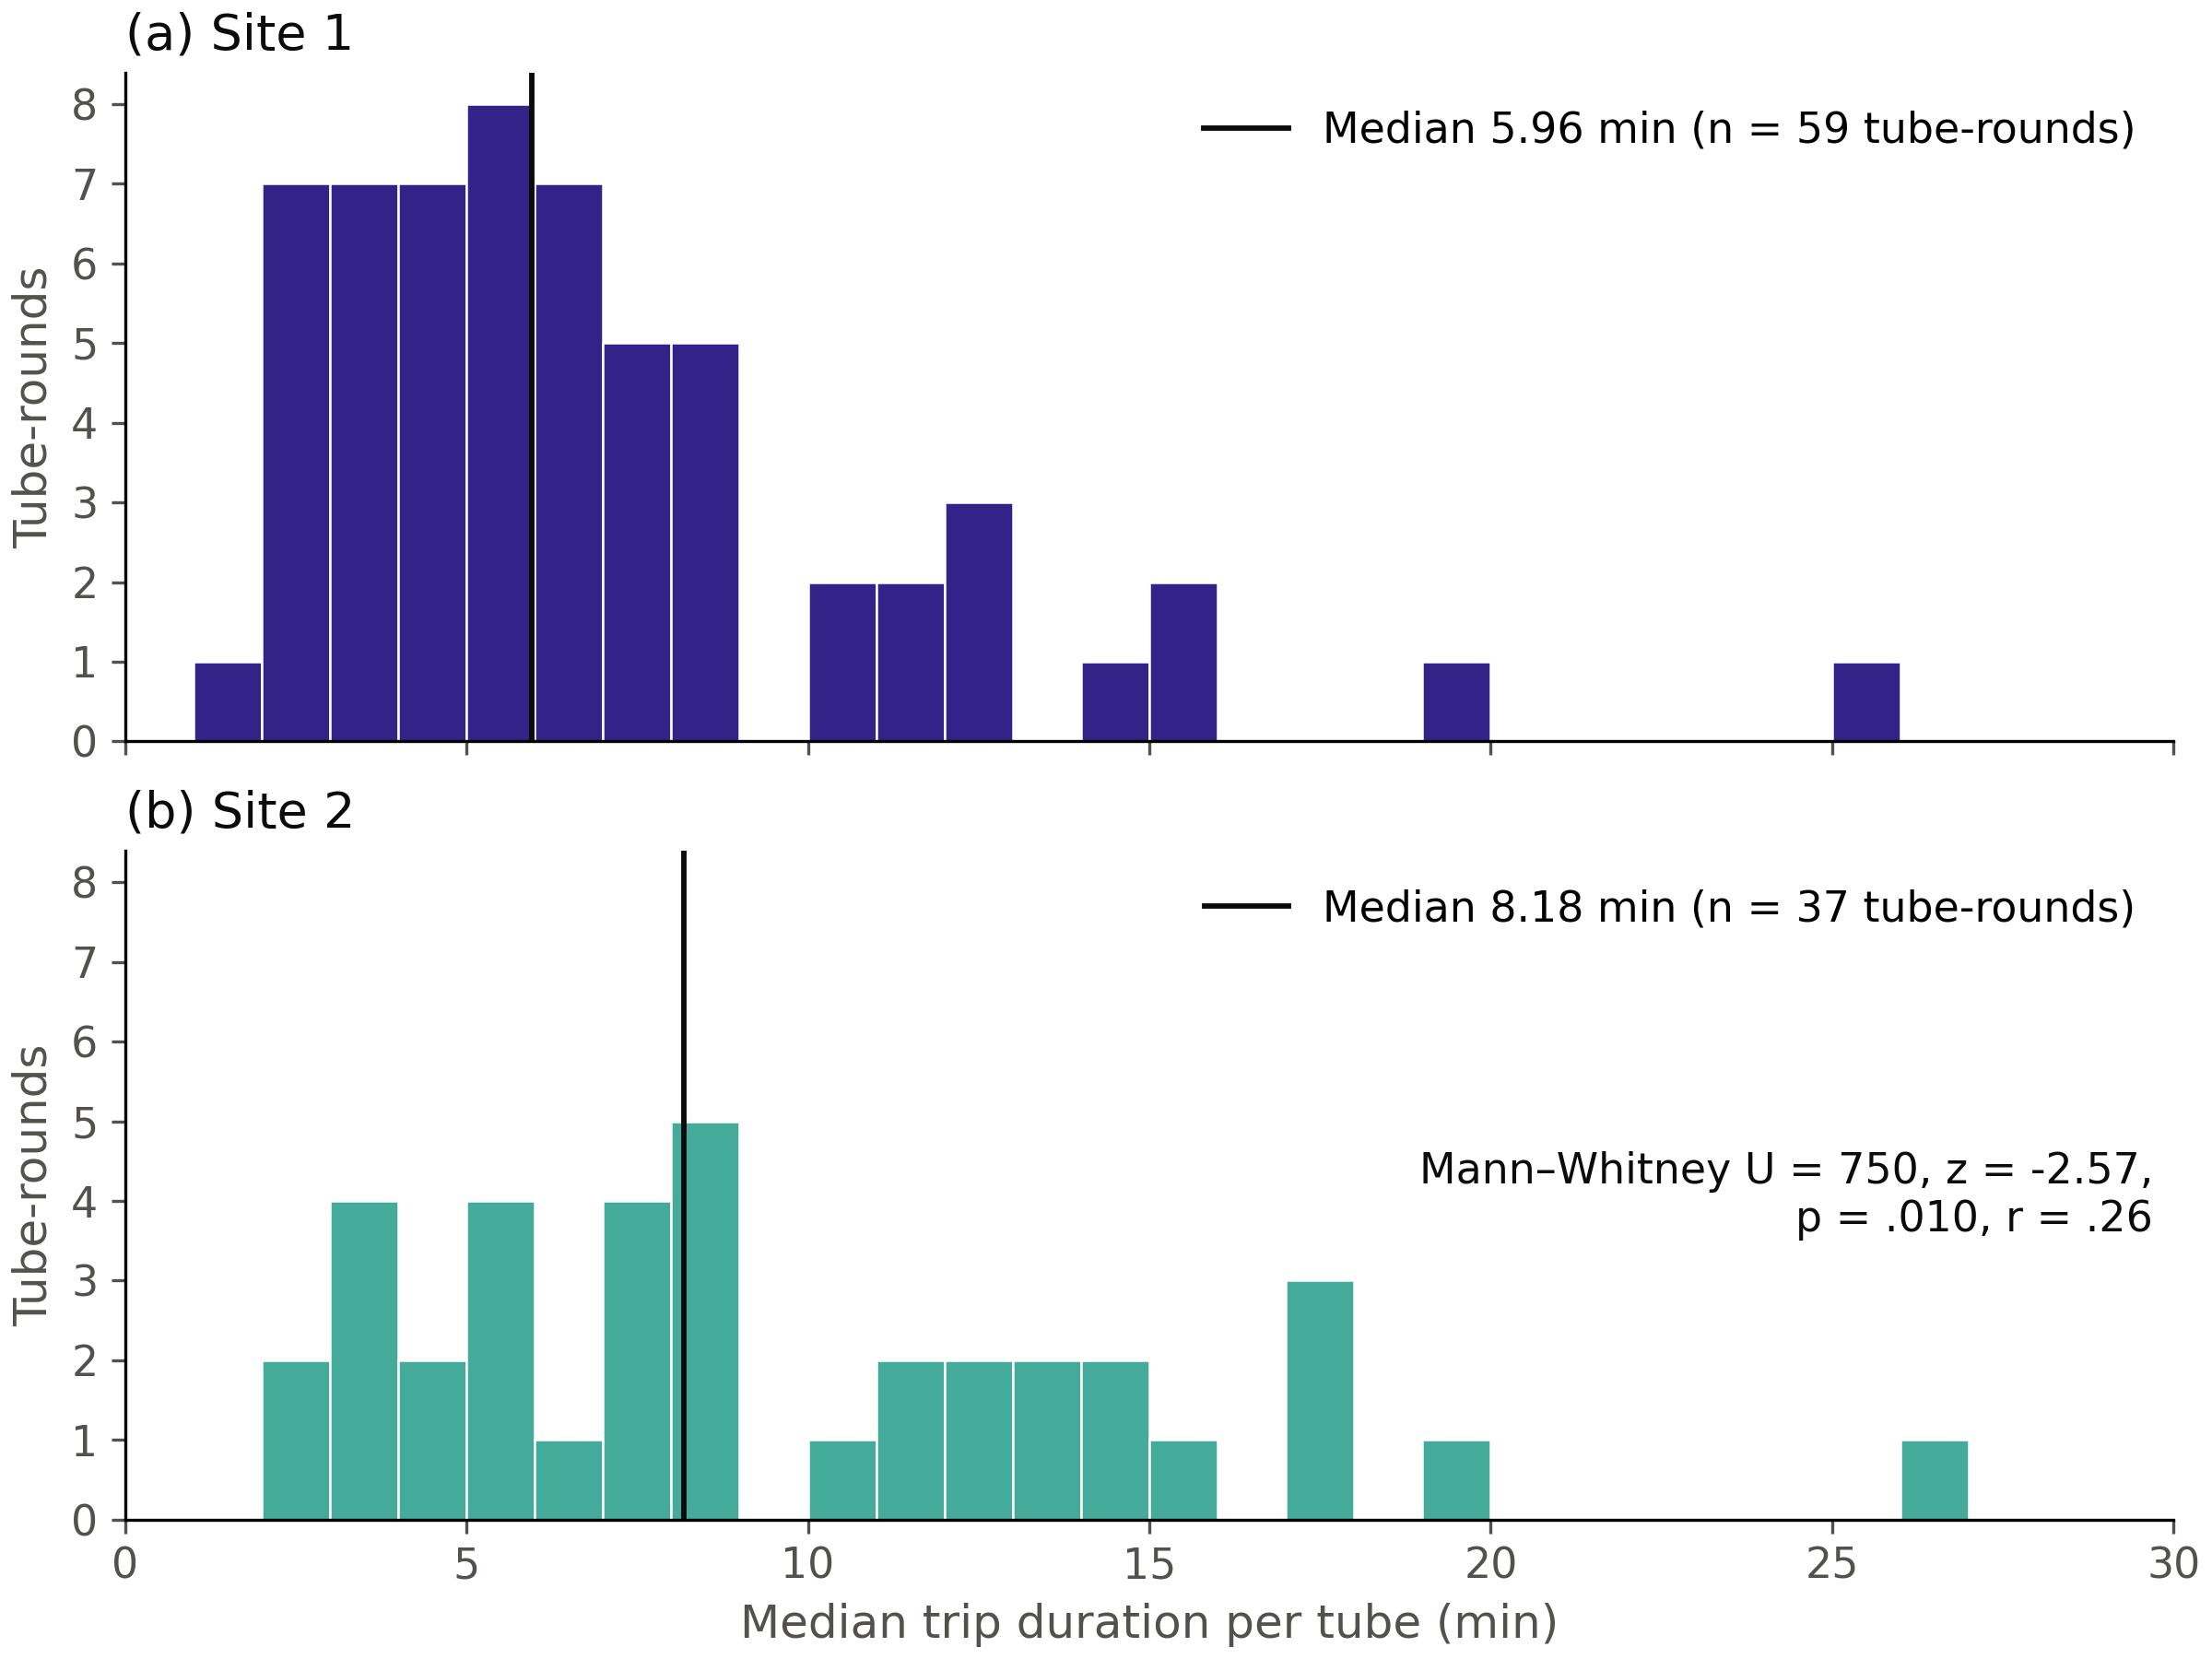

U    750.000
z     -2.571
p      0.010
r      0.262
dtype: float64

In [22]:
def mann_whitney(a: np.ndarray, b: np.ndarray) -> dict:
    res = mannwhitneyu(a, b)
    n1, n2 = len(a), len(b)
    N = n1 + n2
    _, ties = np.unique(np.r_[a, b], return_counts=True)
    sd = np.sqrt(n1 * n2 / 12 * ((N + 1) - (ties ** 3 - ties).sum() / (N * (N - 1))))
    z = (res.statistic - n1 * n2 / 2) / sd
    return dict(U=res.statistic, z=z, p=res.pvalue, r=abs(z) / np.sqrt(N))


prov = nests[nests["provision"].str.contains(PROVISIONED, na=False)]
keep = set(zip(prov["release"], prov["site_name"], prov["tube"]))
t = trips[[k in keep for k in zip(trips["release"], trips["site_name"], trips["tube"])]]
tube_med = (t["duration_sec"] / 60).groupby([t["site_name"], t["release"], t["tube"]]).median()
mw = mann_whitney(tube_med.loc["mendels"].to_numpy(), tube_med.loc["natalies"].to_numpy())

apply_style()
max_min = int(np.ceil(tube_med.max() / 10) * 10)
bins = np.arange(0, max_min + 1, 1)
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True, sharey=True, constrained_layout=True)
for i, (ax, site) in enumerate(zip(axes, sorted(SITE_LABELS))):
    m = tube_med.loc[site].to_numpy()
    ax.hist(m, bins=bins, color=SITE_COLORS[site], edgecolor="white", linewidth=0.6)
    ax.axvline(np.median(m), color=INK, lw=1.4, label=f"Median {np.median(m):.2f} min (n = {len(m)} tube-rounds)")
    ax.legend(loc="upper right", frameon=False, fontsize=11)
    ax.set_title(f"({'ab'[i]}) {SITE_LABELS[site]}", loc="left", color=INK)
    ax.set_ylabel("Tube-rounds", color=MUTED)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
p_txt = "p < .001" if mw["p"] < 0.001 else f"p = {mw['p']:.3f}".replace("0.", ".")
axes[1].text(0.99, 0.55, f"Mann–Whitney U = {mw['U']:.0f}, z = {mw['z']:.2f},\n{p_txt}, r = {mw['r']:.2f}".replace("0.", "."),
             transform=axes[1].transAxes, ha="right", va="top", color=INK, fontsize=11)
axes[-1].set_xlabel("Median trip duration per tube (min)", color=MUTED)
axes[-1].set_xlim(0, max_min)
save(fig, "fig_trip_duration", width=750)

pd.Series(mw).round(3)

In [23]:
### manual analysis by self #

In [24]:
# figure 1

In [2]:
files = pd.read_csv(DATA / "files.csv")

In [3]:
files.columns.tolist()

['video_title',
 'site_name',
 'device_name',
 'date',
 'start_time',
 'end_time',
 'time_zone',
 'clip_start',
 'clip_end',
 'time_source',
 'filename_time',
 'duration_min',
 'fps',
 'size_mb',
 'run_status',
 'failure_cause',
 'failure_detail',
 'next_step',
 'error',
 'gpu_hours',
 'clip_reviewed',
 'reviewed_by',
 'events',
 'events_reviewed',
 'events_accepted',
 'events_rejected',
 'events_added',
 'run_id',
 'video_id']

In [15]:
files['run_status'].value_counts()

run_status
completed    5930
failed        375
Name: count, dtype: int64

In [17]:
files[files["run_status"].eq("completed")].groupby("site_name").agg(hours=("duration_min", lambda m: round(m.sum() / 60)),
                                                                     days=("date", "nunique"),
                                                                     clips=("video_title", "size")).rename(index=SITE_LABELS)

,hours,days,clips
site_name,,,
Site 1,458,50,2777
Site 2,522,46,3153


In [18]:
458+522

980

In [19]:
files[files["run_status"].eq("failed")].groupby("site_name").agg(hours=("duration_min", lambda m: round(m.sum() / 60)),
                                                                     days=("date", "nunique"),
                                                                     clips=("video_title", "size")).rename(index=SITE_LABELS)

,hours,days,clips
site_name,,,
Site 1,0,50,321
Site 2,0,35,54


In [24]:
2777+3153

5930

In [25]:
# figure one is confirmed. There are 980 hours of usable video from (2777+3153 = 5930 10 mins clips)

In [26]:
# figure 2

In [28]:
events = pd.read_csv(DATA / "review_events.csv")

In [30]:
events.columns.tolist()

['video_title',
 'clip_start',
 'device_id',
 'device_name',
 'site_name',
 'location',
 'timestamp',
 'clip_sec',
 'track_id',
 'action',
 'reference',
 'duration_sec',
 'at_edge',
 'review',
 'reviewed_by',
 'review_notes',
 'species',
 'species_confidence',
 'species_votes',
 'species_vote_share',
 'group',
 'group_share',
 'counted',
 'marker_id',
 'marker_votes',
 'marker_vote_share',
 'clip_reviewed']

In [31]:
events['review'].value_counts()

review
accepted    3001
rejected     503
added        241
disputed       6
Name: count, dtype: int64

In [32]:
events[events['review'] == 'disputed']

,video_title,clip_start,device_id,device_name,site_name,location,timestamp,clip_sec,track_id,action,...,species_confidence,species_votes,species_vote_share,group,group_share,counted,marker_id,marker_votes,marker_vote_share,clip_reviewed
1039,mendels_2024-05-23_15_00_00,2024-05-23T15:00:00.000+00:00,NaN,NaN,mendels,NaN,2024-05-23T15:00:22.493+00:00,22.493,5.0,exit,...,0.3505,25.0,0.200,Bees,0.866,yes,NaN,NaN,NaN,True
2226,natalies_2024-05-28_14_40_00,2024-05-28T14:40:00.000+00:00,NaN,NaN,natalies,NaN,2024-05-28T14:42:13.618+00:00,133.618,3.0,exit,...,0.1423,25.0,0.109,Wasps,0.756,yes,NaN,NaN,NaN,True
2253,natalies_2024-05-28_14_00_00,2024-05-28T14:00:00.000+00:00,NaN,NaN,natalies,NaN,2024-05-28T14:01:03.710+00:00,63.710,1.0,stay,...,0.1084,34.0,0.829,Unclear,1.000,yes,NaN,NaN,NaN,True
2254,natalies_2024-05-28_14_00_00,2024-05-28T14:00:00.000+00:00,NaN,NaN,natalies,NaN,2024-05-28T14:01:11.774+00:00,71.774,2.0,stay,...,0.0505,14.0,0.583,Other crawlers,0.667,yes,NaN,NaN,NaN,True
2255,natalies_2024-05-28_14_00_00,2024-05-28T14:00:00.000+00:00,NaN,NaN,natalies,NaN,2024-05-28T14:03:40.486+00:00,220.486,3.0,stay,...,0.0855,4.0,0.571,Unclear,0.000,yes,NaN,NaN,NaN,True
2267,natalies_2024-05-28_13_40_01,2024-05-28T13:40:01.000+00:00,NaN,NaN,natalies,NaN,2024-05-28T13:40:16.894+00:00,15.894,1.0,enter,...,0.2165,50.0,0.164,Wasps,0.707,yes,NaN,NaN,NaN,True
